# ParFlow-CLM vs Ameriflux Comparison

Load model output from Notebook 2, fetch Ameriflux tower observations, and evaluate:
- Daily latent heat time series
- Scatter plot with 1:1 line
- ET component breakdown
- Soil moisture
- Forcing quality check (CW3E vs Ameriflux downward shortwave)
- Metrics: KGE, NSE, RMSE, bias

In [99]:
import os
import sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import hf_hydrodata as hf
from pathlib import Path
from datetime import datetime

# Make helpers.py (at repo root) importable from this subdir
sys.path.insert(0, os.path.abspath(".."))
from helpers import read_site_config

# HydroData PIN (persists from Notebook 1, but register again if needed)
hf.register_api_pin("lt0663@princeton.edu", "0601")


### Original Code - I didn't change anything here

In [100]:
# ============================================================
# Load Site Configuration
# ============================================================
static_write_dir = "../runs/et/US_Ro1_WY2016_BALLBERRY"

run_dir = Path(static_write_dir)
cfg = read_site_config(run_dir / "site_config.txt")

site_id    = cfg["site_id"]
water_year = int(cfg["water_year"])
start      = cfg["start"]
end        = cfg["end"]
lat        = float(cfg["lat"])
lon        = float(cfg["lon"])
utc_offset = int(cfg["utc_offset"])
porosity   = float(cfg["soil_porosity"])

print(f"Site: {site_id}, WY{water_year}, UTC offset: {utc_offset}")


Site: US-Ro1, WY2016, UTC offset: -6


In [101]:
# ============================================================
# Load Model Output
# ============================================================
run_dir = Path(static_write_dir)
clm_files = sorted(run_dir.glob("*.out.CLM.*.nc"))
pf_files = sorted(run_dir.glob("*.out.00001.nc"))

if not clm_files:
    raise FileNotFoundError(f"No CLM output in {run_dir}. Run Notebook 2 first.")

clm_ds = xr.open_dataset(clm_files[0])
n_steps = len(clm_ds["eflx_lh_tot"].values.flatten())

# Build datetime index with CLM end-of-hour shift
# CLM timestamps are end-of-hour: value at T represents avg during T-1 to T
# Shift back 1h so timestamps align with the hour the flux occurred in
dt_start = datetime.strptime(start, "%Y-%m-%d")
model_dates = pd.date_range(dt_start, periods=n_steps, freq="h") - pd.Timedelta(hours=1)

# Extract hourly LH
model_lh_hourly = pd.Series(
    clm_ds["eflx_lh_tot"].values.flatten(),
    index=model_dates, name="model_lh"
)

print(f"Loaded {n_steps} hourly time steps")
print(f"  LH range: {model_lh_hourly.min():.1f} to {model_lh_hourly.max():.1f} W/m2")

Loaded 8784 hourly time steps
  LH range: -23.7 to 505.2 W/m2


In [102]:
# ============================================================
# Fetch Ameriflux Observations
# ============================================================
obs_df = hf.get_point_data(
    dataset="ameriflux", variable="latent_heat",
    temporal_resolution="hourly", aggregation="sum",
    date_start=start, date_end=end, site_ids=site_id,
)

obs_dates = pd.to_datetime(obs_df["date"])
obs_lh_hourly = pd.Series(
    obs_df[site_id].values.astype(float),
    index=pd.DatetimeIndex(obs_dates), name="obs_lh"
)
obs_lh_hourly = obs_lh_hourly.replace(-9999, np.nan).dropna()

print(f"Ameriflux observations: {len(obs_lh_hourly)} valid hourly values")
print(f"  LH range: {obs_lh_hourly.min():.1f} to {obs_lh_hourly.max():.1f} W/m2")

Ameriflux observations: 8785 valid hourly values
  LH range: -76.9 to 960.0 W/m2


In [103]:
# ============================================================
# Resample to Daily Means (in local time)
# ============================================================
# Shift to local time for daily binning (midnight-to-midnight local),
# then shift index back so dates stay in UTC calendar.

def hourly_to_daily(hourly, utc_off):
    """Resample hourly UTC series to daily means in local time."""
    shifted = hourly.copy()
    delta = pd.Timedelta(hours=utc_off)
    shifted.index = shifted.index + delta
    daily = shifted.resample("D").mean()
    daily.index = daily.index - delta
    return daily.dropna()

obs_daily = hourly_to_daily(obs_lh_hourly, utc_offset)
mod_daily = hourly_to_daily(model_lh_hourly, utc_offset)

print(f"Daily obs: {len(obs_daily)} days")
print(f"Daily mod: {len(mod_daily)} days")

Daily obs: 367 days
Daily mod: 367 days


In [104]:
# ============================================================
# Compute Metrics
# ============================================================
common = obs_daily.index.intersection(mod_daily.index)
obs_c = obs_daily.loc[common].dropna()
mod_c = mod_daily.loc[common].dropna()
common = obs_c.index.intersection(mod_c.index)
obs_c = obs_c.loc[common]
mod_c = mod_c.loc[common]

bias = float((mod_c - obs_c).mean())
rmse = float(np.sqrt(((mod_c - obs_c) ** 2).mean()))
r = float(np.corrcoef(obs_c, mod_c)[0, 1])

# KGE (Gupta et al. 2009)
mu_o, mu_m = obs_c.mean(), mod_c.mean()
sigma_o, sigma_m = obs_c.std(), mod_c.std()
kge = float(1 - np.sqrt((r - 1)**2 + (sigma_m/sigma_o - 1)**2 + (mu_m/mu_o - 1)**2))

# NSE
ss_res = ((mod_c - obs_c) ** 2).sum()
ss_tot = ((obs_c - mu_o) ** 2).sum()
nse = float(1 - ss_res / ss_tot) if ss_tot > 0 else np.nan

# Annual ET (from daily LH)
lv = 2.45e6  # J/kg (latent heat of vaporization)
obs_et = float((obs_c / lv * 86400).sum())  # mm/yr
mod_et = float((mod_c / lv * 86400).sum())

print(f"\\n{'='*50}")
print(f"  {site_id} WY{water_year} — Daily LH Metrics")
print(f"{'='*50}")
print(f"  N days:     {len(common)}")
print(f"  Bias:       {bias:+.1f} W/m2")
print(f"  RMSE:       {rmse:.1f} W/m2")
print(f"  r:          {r:.3f}")
print(f"  KGE:        {kge:.3f}")
print(f"  NSE:        {nse:.3f}")
print(f"  Obs ET:     {obs_et:.0f} mm/yr")
print(f"  Model ET:   {mod_et:.0f} mm/yr")
print(f"{'='*50}")

\n==================================================
  US-Ro1 WY2016 — Daily LH Metrics
  N days:     367
  Bias:       +1.4 W/m2
  RMSE:       43.0 W/m2
  r:          0.724
  KGE:        0.656
  NSE:        0.519
  Obs ET:     812 mm/yr
  Model ET:   830 mm/yr


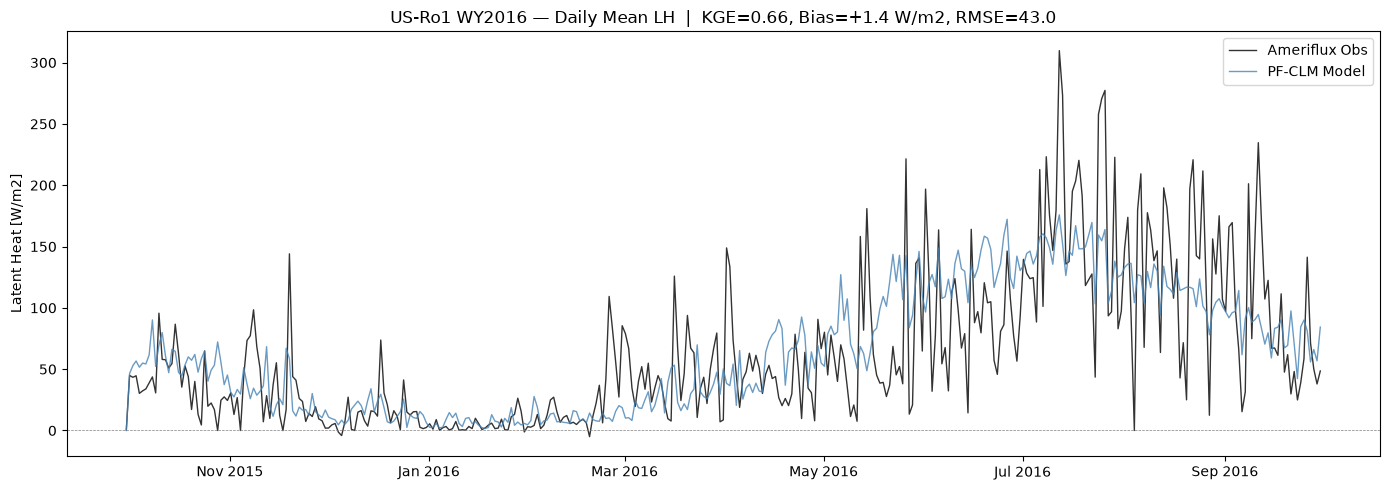

In [105]:
# ============================================================
# Time Series Plot — Daily Latent Heat
# ============================================================
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(obs_c.index, obs_c.values, color="black", lw=1.0, label="Ameriflux Obs", alpha=0.8)
ax.plot(mod_c.index, mod_c.values, color="steelblue", lw=1.0, label="PF-CLM Model", alpha=0.8)

ax.set_ylabel("Latent Heat [W/m2]")
ax.set_title(f"{site_id} WY{water_year} — Daily Mean LH  |  "
             f"KGE={kge:.2f}, Bias={bias:+.1f} W/m2, RMSE={rmse:.1f}")
ax.legend(loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.axhline(0, color="gray", lw=0.5, ls="--")
plt.tight_layout()
plt.show()

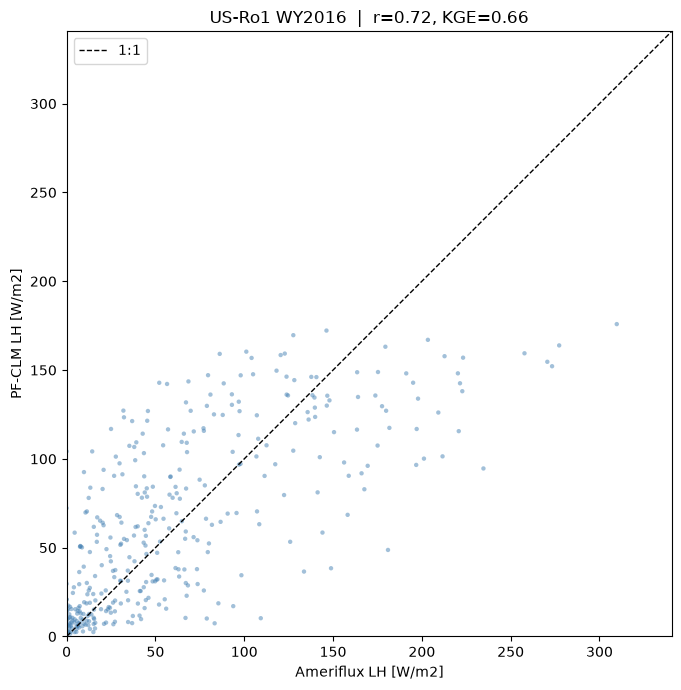

In [106]:
# ============================================================
# Scatter Plot — Observed vs Modeled
# ============================================================
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(obs_c.values, mod_c.values, s=10, alpha=0.5, color="steelblue", edgecolors="none")

# 1:1 line
lim_max = max(obs_c.max(), mod_c.max()) * 1.1
ax.plot([0, lim_max], [0, lim_max], "k--", lw=1, label="1:1")
ax.set_xlim(0, lim_max)
ax.set_ylim(0, lim_max)

ax.set_xlabel("Ameriflux LH [W/m2]")
ax.set_ylabel("PF-CLM LH [W/m2]")
ax.set_title(f"{site_id} WY{water_year}  |  r={r:.2f}, KGE={kge:.2f}")
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()
plt.show()

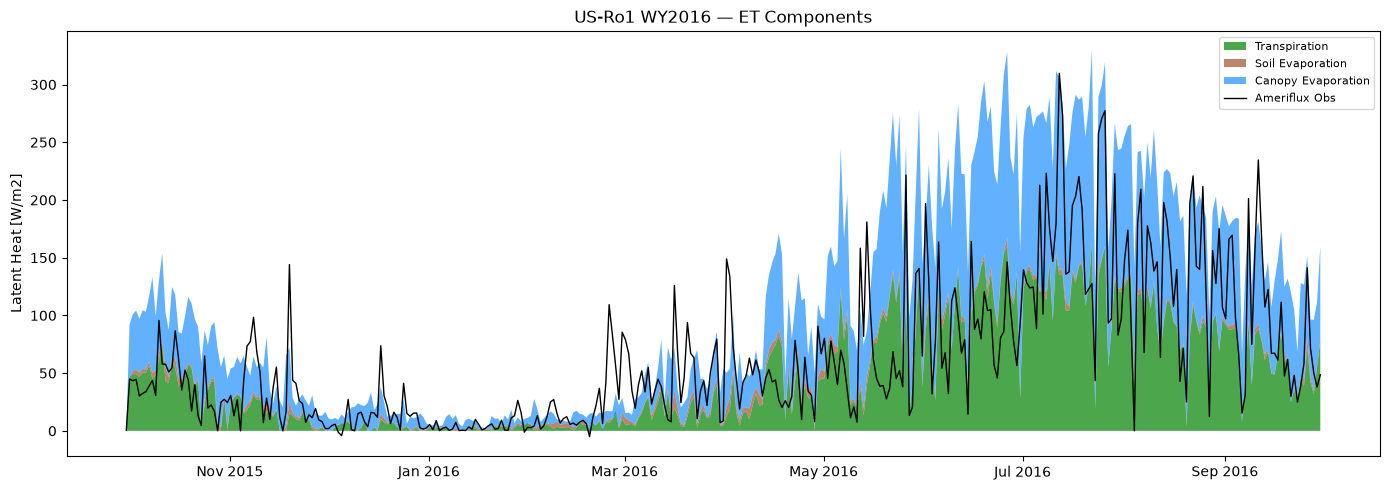

In [107]:
# ============================================================
# ET Components — Stacked Area + Obs Overlay
# ============================================================
et_vars = {
    "qflx_tran_veg": ("Transpiration", "green"),
    "qflx_evap_soi": ("Soil Evaporation", "sienna"),
    "qflx_evap_veg": ("Canopy Evaporation", "dodgerblue"),
}

fig, ax = plt.subplots(figsize=(14, 5))

# Convert each component to daily LH (W/m2) using Lv
lv = 2.45e6
et_daily = {}
for var, (label, color) in et_vars.items():
    if var in clm_ds:
        hourly = pd.Series(clm_ds[var].values.flatten(), index=model_dates)
        daily = hourly_to_daily(hourly, utc_offset) * lv  # mm/s -> W/m2
        et_daily[label] = daily

if et_daily:
    et_df = pd.DataFrame(et_daily).reindex(mod_daily.index).fillna(0)
    colors = [et_vars[v][1] for v in et_vars if et_vars[v][0] in et_df.columns]
    ax.stackplot(et_df.index, *[et_df[col] for col in et_df.columns],
                 labels=et_df.columns, colors=colors, alpha=0.7)

ax.plot(obs_c.index, obs_c.values, "k-", lw=1.0, label="Ameriflux Obs")
ax.set_ylabel("Latent Heat [W/m2]")
ax.set_title(f"{site_id} WY{water_year} — ET Components")
ax.legend(loc="upper right", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()

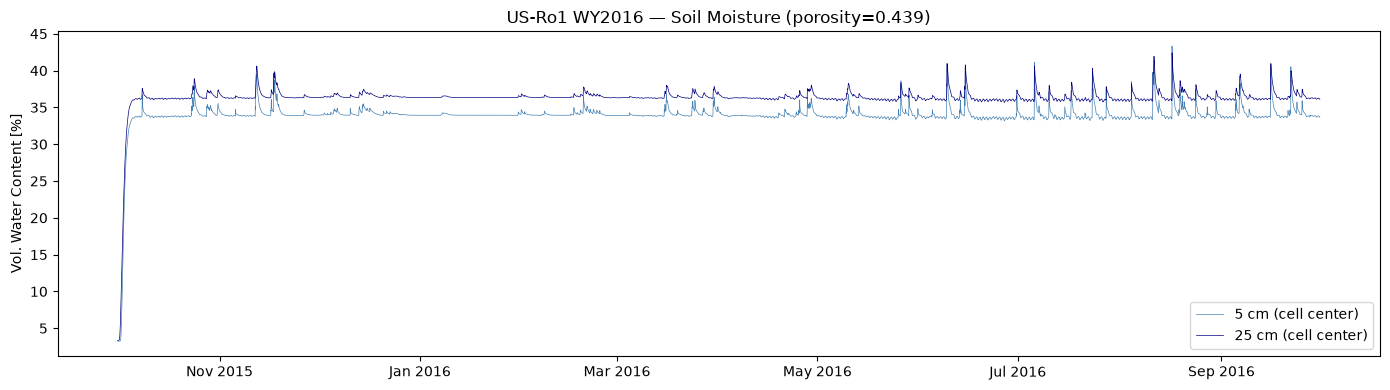

In [108]:
# ============================================================
# Soil Moisture — Top 2 Layers from ParFlow
# ============================================================
if pf_files:
    pf_ds = xr.open_dataset(pf_files[0])
    if "saturation" in pf_ds:
        sat = pf_ds["saturation"]
        pf_dates = pd.date_range(start, periods=sat.shape[0], freq="h")

        fig, ax = plt.subplots(figsize=(14, 4))
        ax.plot(pf_dates, sat[:, 9, 0, 0].values * porosity * 100,
                lw=0.5, color="steelblue", label="5 cm (cell center)")
        ax.plot(pf_dates, sat[:, 8, 0, 0].values * porosity * 100,
                lw=0.5, color="navy", label="25 cm (cell center)")
        ax.set_ylabel("Vol. Water Content [%]")
        ax.set_title(f"{site_id} WY{water_year} — Soil Moisture (porosity={porosity})")
        ax.legend()
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        plt.tight_layout()
        plt.show()
    pf_ds.close()
else:
    print("No ParFlow pressure/saturation NetCDF output found.")

Forcing quality check: US-Ro1 WY2016

  SWdown  : bias=+13.25 W/m2, RMSE=98.38, r=0.92 (8784 hrs)
  LWdown  : bias=-13.93 W/m2, RMSE=29.58, r=0.90 (8745 hrs)
  Tair    : bias=+0.03 C, RMSE=2.00, r=0.99 (8784 hrs)
  Wind    : bias=+1.46 m/s, RMSE=1.97, r=0.75 (8777 hrs)
  VPD     : bias=-0.01 hPa, RMSE=2.34, r=0.89 (8784 hrs)


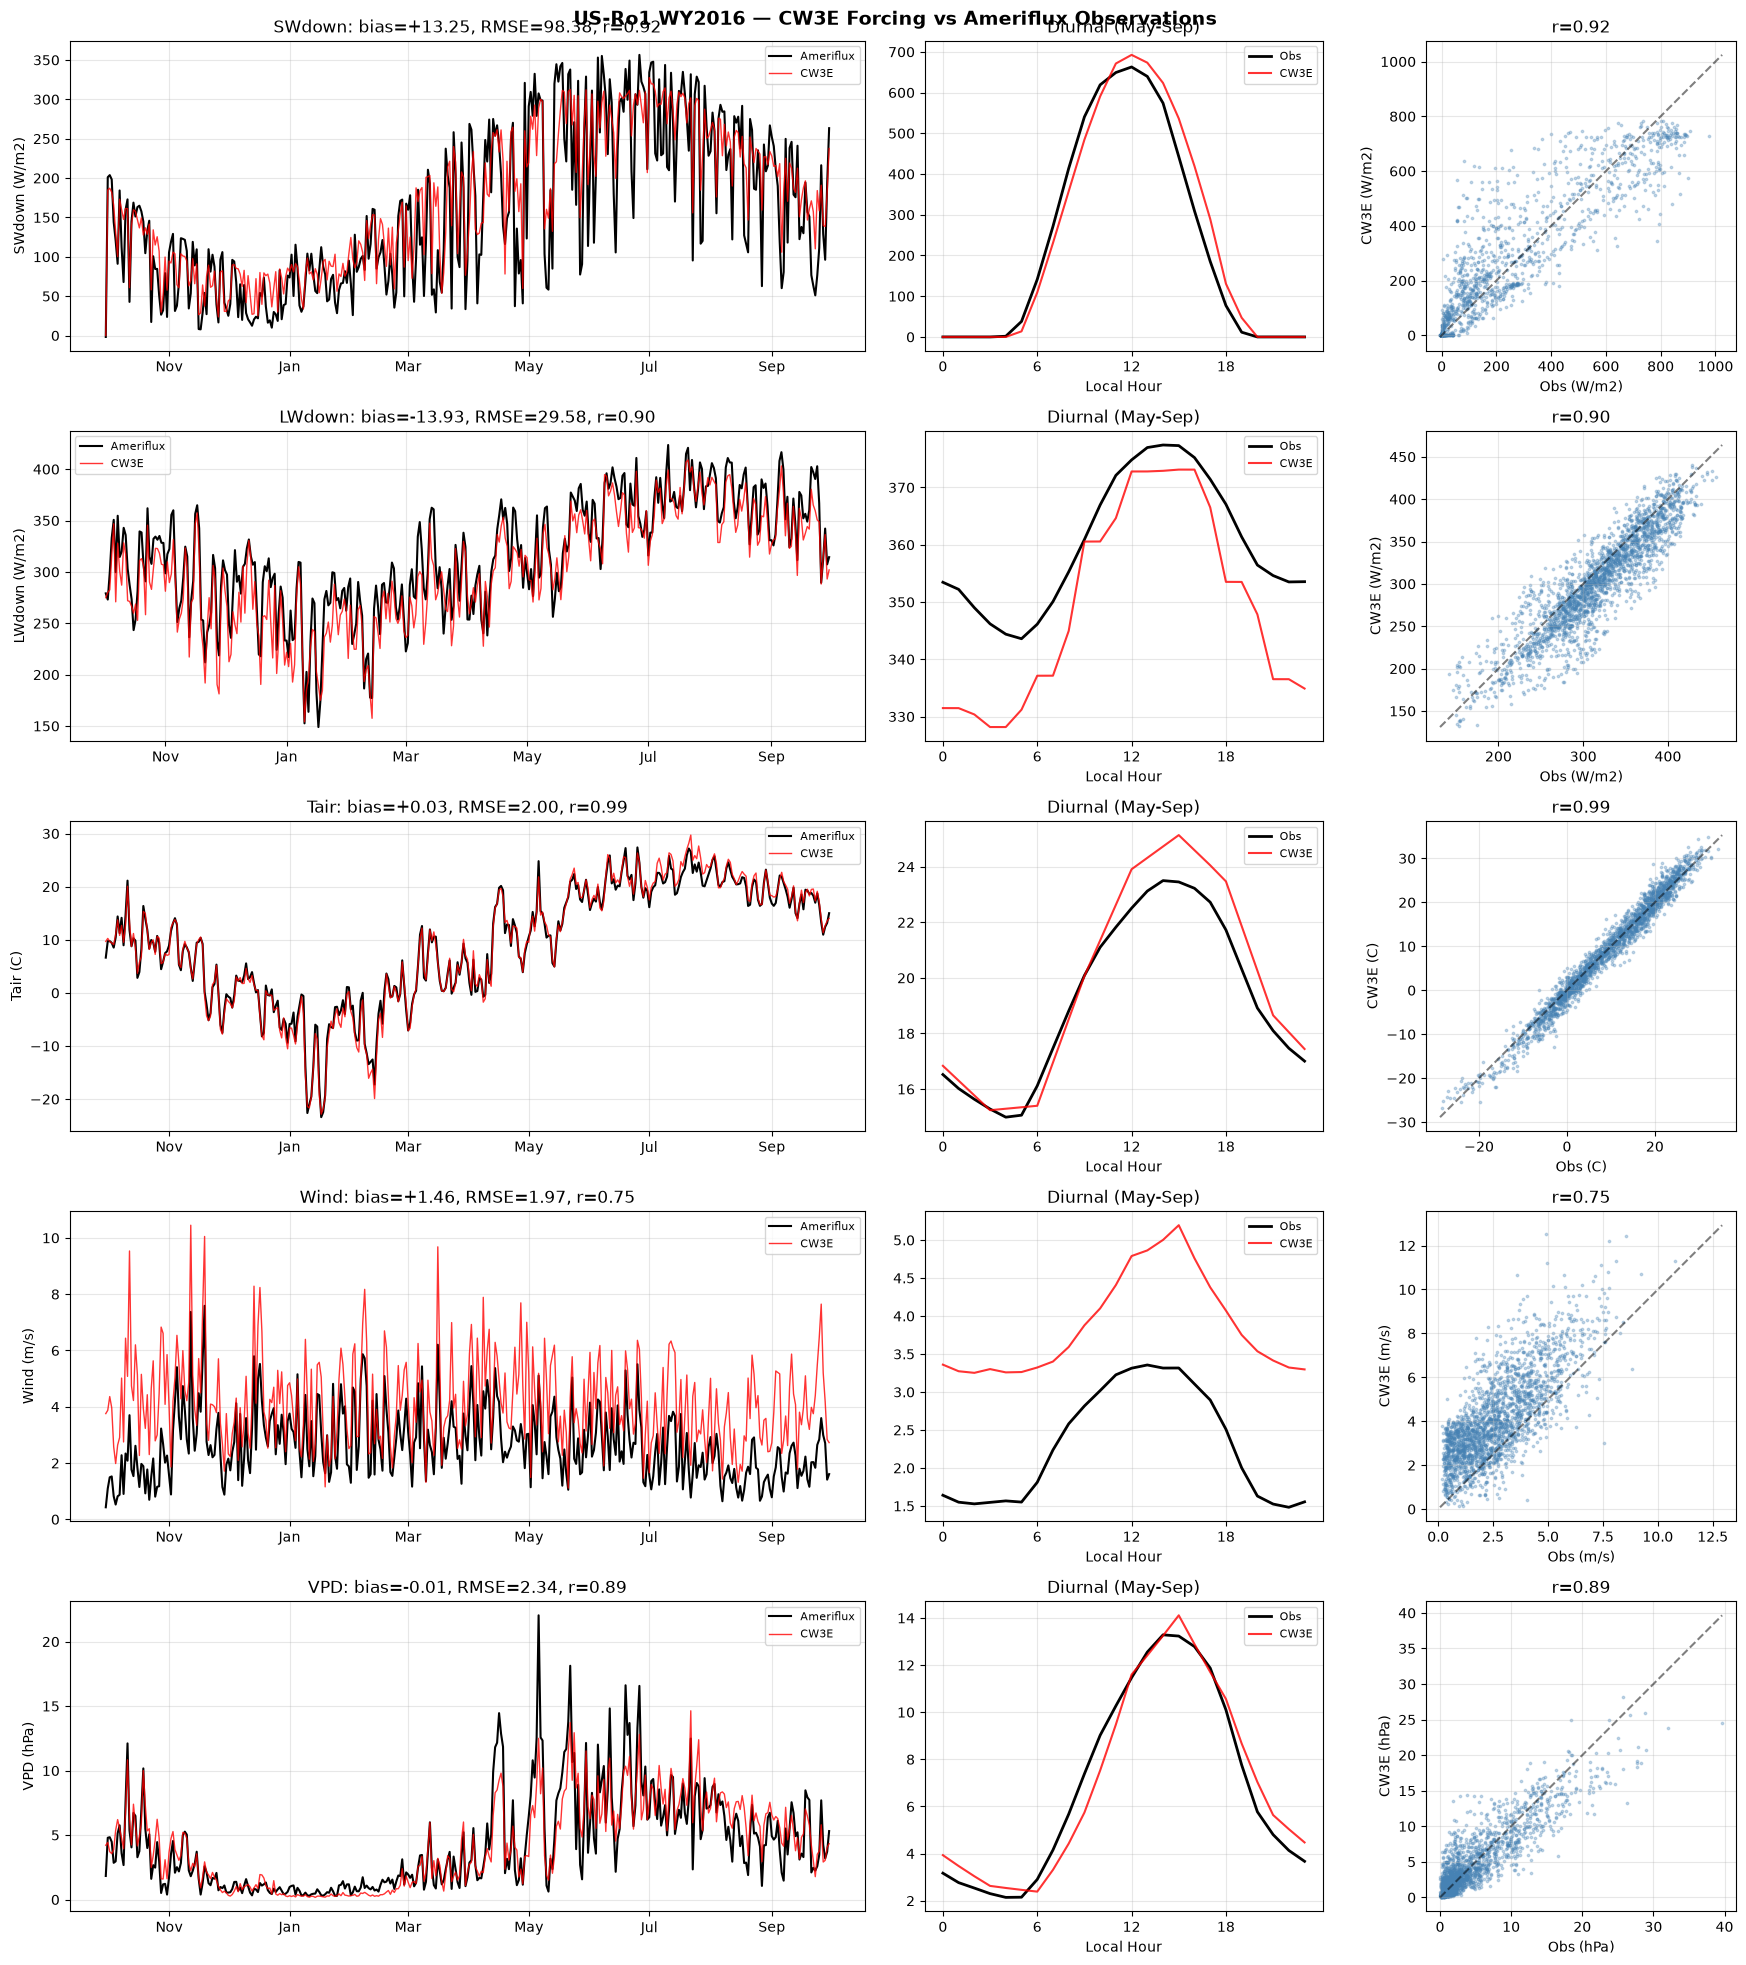

In [109]:
# ============================================================
# Forcing Quality — CW3E vs Ameriflux (5 variables)
# ============================================================
# Compare: SWdown, LWdown, Tair, Wind speed, VPD
# Not all variables are available at all sites — skips missing ones.

# Load CW3E forcing
forcing_path = run_dir / cfg["forcing_file"]
forcing_raw = np.loadtxt(forcing_path)
forc_dates = pd.date_range(start, periods=len(forcing_raw), freq="h")
# Shift to local time for diurnal/daily comparisons
forc_dates_local = forc_dates + pd.Timedelta(hours=utc_offset)

forcing_df = pd.DataFrame(forcing_raw, index=forc_dates_local,
    columns=["dswr", "dlwr", "precip", "temp_k", "ugrd", "vgrd", "press", "spfh"])
forcing_df["temp_c"] = forcing_df["temp_k"] - 273.15
forcing_df["wind_speed"] = np.sqrt(forcing_df["ugrd"]**2 + forcing_df["vgrd"]**2)

# VPD: e = q*P/(0.622+0.378*q), esat = 611.2*exp(17.67*Tc/(Tc+243.5)), VPD = (esat-e)/100
q, P, Tc = forcing_df["spfh"], forcing_df["press"], forcing_df["temp_c"]
e = q * P / (0.622 + 0.378 * q)
esat = 611.2 * np.exp(17.67 * Tc / (Tc + 243.5))
forcing_df["vpd_hpa"] = ((esat - e) / 100.0).clip(lower=0)

# Variables to compare: (display_name, ameriflux_var, aggregation, forcing_col, unit)
var_map = [
    ("SWdown", "downward_shortwave", "mean", "dswr",       "W/m2"),
    ("LWdown", "downward_longwave",  "mean", "dlwr",       "W/m2"),
    ("Tair",   "air_temp",           "mean", "temp_c",     "C"),
    ("Wind",   "wind_speed",         "mean", "wind_speed", "m/s"),
    ("VPD",    "vapor_pressure_deficit", "mean", "vpd_hpa", "hPa"),
]

# Fetch obs and compute metrics for each variable
results = {}
obs_data = {}
print(f"Forcing quality check: {site_id} WY{water_year}\n")

for disp, obs_var, agg, forc_col, unit in var_map:
    try:
        df = hf.get_point_data(
            dataset="ameriflux", variable=obs_var,
            temporal_resolution="hourly", aggregation=agg,
            date_start=start, date_end=end, site_ids=site_id,
        )
        if df is None or df.empty or site_id not in df.columns:
            print(f"  {disp:<8}: no data available")
            continue
        obs = pd.Series(df[site_id].values.astype(float),
                        index=pd.to_datetime(df["date"])).replace(-9999, np.nan).dropna()
        # Shift to local time
        obs.index = obs.index + pd.Timedelta(hours=utc_offset)
        # Temperature: Ameriflux is in C, forcing temp_c is also C
        # But if obs_var is air_temp, Ameriflux may be in K — check range
        if obs_var == "air_temp" and obs.median() > 200:
            obs = obs - 273.15  # K -> C

        obs_data[disp] = obs
        forc = forcing_df[forc_col]

        common = forc.index.intersection(obs.index)
        f_c = forc.loc[common].dropna()
        o_c = obs.loc[common].dropna()
        common = f_c.index.intersection(o_c.index)
        if len(common) < 100:
            print(f"  {disp:<8}: insufficient overlap ({len(common)} hours)")
            continue
        f_c, o_c = f_c.loc[common], o_c.loc[common]

        bias = float((f_c - o_c).mean())
        rmse = float(np.sqrt(((f_c - o_c)**2).mean()))
        r = float(np.corrcoef(f_c, o_c)[0, 1])
        results[disp] = {"bias": bias, "rmse": rmse, "r": r, "unit": unit, "n": len(common)}
        print(f"  {disp:<8}: bias={bias:+.2f} {unit}, RMSE={rmse:.2f}, r={r:.2f} ({len(common)} hrs)")
    except Exception as e:
        print(f"  {disp:<8}: skipped ({e})")

if not results:
    print("\nNo forcing comparison data available for this site.")
else:
    # Multi-panel plot: daily time series, diurnal (May-Sep), scatter
    vars_ok = [v for v in ["SWdown", "LWdown", "Tair", "Wind", "VPD"] if v in results]
    n_vars = len(vars_ok)

    fig, axes = plt.subplots(n_vars, 3, figsize=(18, 4 * n_vars),
                             gridspec_kw={"width_ratios": [3, 1.5, 1.5]})
    if n_vars == 1:
        axes = axes.reshape(1, -1)

    forc_col_map = {"SWdown": "dswr", "LWdown": "dlwr", "Tair": "temp_c",
                    "Wind": "wind_speed", "VPD": "vpd_hpa"}

    for row, var in enumerate(vars_ok):
        m = results[var]
        forc = forcing_df[forc_col_map[var]]
        obs = obs_data[var]

        common = forc.index.intersection(obs.dropna().index)
        f_c = forc.loc[common]
        o_c = obs.loc[common].dropna()
        common = f_c.index.intersection(o_c.index)
        f_c, o_c = f_c.loc[common], o_c.loc[common]

        # Panel 1: Daily time series
        ax = axes[row, 0]
        ax.plot(o_c.resample("D").mean(), "k-", lw=1.5, label="Ameriflux")
        ax.plot(f_c.resample("D").mean(), "r-", lw=1, alpha=0.8, label="CW3E")
        ax.set_ylabel(f"{var} ({m['unit']})")
        ax.set_title(f"{var}: bias={m['bias']:+.2f}, RMSE={m['rmse']:.2f}, r={m['r']:.2f}")
        ax.legend(fontsize=8)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        ax.grid(True, alpha=0.3)

        # Panel 2: Diurnal cycle (May-Sep)
        ax = axes[row, 1]
        gs = (common.month >= 5) & (common.month <= 9)
        if gs.sum() > 100:
            ax.plot(o_c.loc[common[gs]].groupby(o_c.loc[common[gs]].index.hour).mean(),
                    "k-", lw=2, label="Obs")
            ax.plot(f_c.loc[common[gs]].groupby(f_c.loc[common[gs]].index.hour).mean(),
                    "r-", lw=1.5, alpha=0.8, label="CW3E")
            ax.set_xlabel("Local Hour")
            ax.set_title("Diurnal (May-Sep)")
            ax.set_xticks(range(0, 24, 6))
            ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

        # Panel 3: Scatter
        ax = axes[row, 2]
        step = max(1, len(f_c) // 2000)
        ax.scatter(o_c.values[::step], f_c.values[::step], s=3, alpha=0.3, color="steelblue")
        lims = [min(o_c.min(), f_c.min()), max(o_c.max(), f_c.max())]
        ax.plot(lims, lims, "k--", alpha=0.5)
        ax.set_xlabel(f"Obs ({m['unit']})")
        ax.set_ylabel(f"CW3E ({m['unit']})")
        ax.set_title(f"r={m['r']:.2f}")
        ax.set_aspect("equal")
        ax.grid(True, alpha=0.3)

    fig.suptitle(f"{site_id} WY{water_year} — CW3E Forcing vs Ameriflux Observations",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

clm_ds.close()

## Assignment Part 3 Starts here!

#### 3.1 Site, water year and two days
select two consecutive summer days with good forcing and complete tower observations. Plot the forcing, observed latent and sensible heat, and both PF-CLM runs for those days.

In [110]:
import matplotlib.colors as mcolors
import matplotlib.dates as mdates

## SET UP SOME CONSTANTS
# here just defining the run directories for simplicity
MEDLYN_PATH = "/workspaces/single_column_PFCLM/runs/et/US_Ro1_WY2016_MEDLYN"
BALL_BERRY_PATH = "/workspaces/single_column_PFCLM/runs/et/US_Ro1_WY2016_BALLBERRY"

# define the two summer days with good forcing and complete tower observations
DAY_ONE = "2016-08-07 00:00:00"  
DAY_TWO = "2016-08-08 23:00:00"

IBM_BLUE = "#648FFF"
IBM_PINK = "#DC267F"
IBM_ORANGE = "#FE6100"
IBM_YELLOW = "#FFB000"
IBM_PURPLE = "#785EF0"


In [111]:
### LOAD IN THE FORCING DATA
forcing_path = run_dir / cfg["forcing_file"]
forcing_raw = np.loadtxt(forcing_path)
forc_dates = pd.date_range(start, periods=len(forcing_raw), freq="h")
# Shift to local time for diurnal/daily comparisons
forc_dates_local = forc_dates + pd.Timedelta(hours=utc_offset)

forcing_df = pd.DataFrame(forcing_raw, index=forc_dates_local,
    columns=["dswr", "dlwr", "precip", "temp_k", "ugrd", "vgrd", "press", "spfh"])
forcing_df["temp_c"] = forcing_df["temp_k"] - 273.15
forcing_df["wind_speed"] = np.sqrt(forcing_df["ugrd"]**2 + forcing_df["vgrd"]**2)

# VPD: e = q*P/(0.622+0.378*q), esat = 611.2*exp(17.67*Tc/(Tc+243.5)), VPD = (esat-e)/100
q, P, Tc = forcing_df["spfh"], forcing_df["press"], forcing_df["temp_c"]
e = q * P / (0.622 + 0.378 * q)
esat = 611.2 * np.exp(17.67 * Tc / (Tc + 243.5))
forcing_df["vpd_hpa"] = ((esat - e) / 100.0).clip(lower=0)
forcing_df.index = pd.to_datetime(forcing_df.index)
forcing_df = forcing_df.loc[DAY_ONE : DAY_TWO]

var_map = [
    ("SWdown", "downward_shortwave", "mean", "dswr",       "W/m2"),
    ("LWdown", "downward_longwave",  "mean", "dlwr",       "W/m2"),
    ("Tair",   "air_temp",           "mean", "temp_c",     "C"),
    ("Wind",   "wind_speed",         "mean", "wind_speed", "m/s"),
    ("VPD",    "vapor_pressure_deficit", "mean", "vpd_hpa", "hPa"),
    ("LE",     "latent_heat",   "sum", "-", "W/m2"),
    ("H",     "sensible_heat",   "sum", "-", "W/m2"),
]

### LOAD IN THE AMERIFLUX DATA
# Fetch obs and compute metrics for each variable
results = {}
obs_data = {}
print(f"Forcing quality check: {site_id} WY{water_year}\n")

for disp, obs_var, agg, forc_col, unit in var_map:
    try:
        df = hf.get_point_data(
            dataset="ameriflux", variable=obs_var,
            temporal_resolution="hourly", aggregation=agg,
            date_start=start, date_end=end, site_ids=site_id,
        )
        if df is None or df.empty or site_id not in df.columns:
            print(f"  {disp:<8}: no data available")
            continue
        obs = pd.Series(df[site_id].values.astype(float),
                        index=pd.to_datetime(df["date"])).replace(-9999, np.nan).dropna()
        # Shift to local time
        obs.index = obs.index + pd.Timedelta(hours=utc_offset)
        # Temperature: Ameriflux is in C, forcing temp_c is also C
        # But if obs_var is air_temp, Ameriflux may be in K — check range
        if obs_var == "air_temp" and obs.median() > 200:
            obs = obs - 273.15  # K -> C

        obs = obs.loc[DAY_ONE:DAY_TWO] # ADDED - now check will be on the subset period
        obs_data[disp] = obs
        
        forc = forcing_df[forc_col].loc[DAY_ONE:DAY_TWO]  # CHANGED - now check will be on the subset period
        
        common = forc.index.intersection(obs.index)
        f_c = forc.loc[common].dropna()
        o_c = obs.loc[common].dropna()
        common = f_c.index.intersection(o_c.index)
        if len(common) < 48:  # CHANGED to just make sure my days have good matching with the forcing
            print(f"  {disp:<8}: insufficient overlap ({len(common)} hours)")
            continue
        f_c, o_c = f_c.loc[common], o_c.loc[common]

        bias = float((f_c - o_c).mean())
        rmse = float(np.sqrt(((f_c - o_c)**2).mean()))
        r = float(np.corrcoef(f_c, o_c)[0, 1])
        results[disp] = {"bias": bias, "rmse": rmse, "r": r, "unit": unit, "n": len(common)}
        print(f"  {disp:<8}: bias={bias:+.2f} {unit}, RMSE={rmse:.2f}, r={r:.2f} ({len(common)} hrs)")
    except Exception as e:
        print(f"  {disp:<8}: skipped ({e})")

obs_df = pd.DataFrame(obs_data)


Forcing quality check: US-Ro1 WY2016



  SWdown  : bias=-36.10 W/m2, RMSE=120.64, r=0.93 (48 hrs)
  LWdown  : bias=-12.64 W/m2, RMSE=19.97, r=0.79 (48 hrs)
  Tair    : bias=+0.22 C, RMSE=1.92, r=0.89 (48 hrs)
  Wind    : bias=+1.28 m/s, RMSE=1.60, r=0.77 (48 hrs)
  VPD     : bias=+1.22 hPa, RMSE=3.67, r=0.78 (48 hrs)
  LE      : skipped ('-')
  H       : skipped ('-')


In [112]:
## HELPER FUNCTION TO READ AND CROP THE DATA TO THE TWO DAYS 
def read_crop_clm(data_dir):
    run_dir = Path(data_dir)
    clm_files = sorted(run_dir.glob("*.out.CLM.*.nc"))
    pf_files = sorted(run_dir.glob("*.out.00001.nc"))

    if not clm_files:
        raise FileNotFoundError(f"No CLM output in {run_dir}. Run Notebook 2 first.")

    clm_ds = xr.open_dataset(clm_files[0])
    pf_ds = xr.open_dataset(pf_files[0])
    n_steps = len(clm_ds["eflx_lh_tot"].values.flatten())

    # append the saturation 

    # Build datetime index with CLM end-of-hour shift
    # CLM timestamps are end-of-hour: value at T represents avg during T-1 to T
    # Shift back 1h so timestamps align with the hour the flux occurred in
    dt_start = datetime.strptime(start, "%Y-%m-%d")
    model_dates = pd.date_range(dt_start, periods=n_steps, freq="h") - pd.Timedelta(hours=1)
    clm_ds['time'] = model_dates 
    clm_ds['time'] = clm_ds['time'] + pd.Timedelta(hours=utc_offset)
    clm_ds_subset = clm_ds.sel(time=slice(DAY_ONE, DAY_TWO))

    pf_ds['time'] = model_dates 
    pf_ds['time'] = pf_ds['time'] + pd.Timedelta(hours=utc_offset)
    pf_ds_subset = pf_ds.sel(time=slice(DAY_ONE, DAY_TWO))

    return clm_ds_subset, pf_ds_subset

clm_ds_ballberry, pf_ds_ballberry = read_crop_clm(BALL_BERRY_PATH)
clm_ds_medlyn, pf_ds_medlyn = read_crop_clm(MEDLYN_PATH)

In [113]:
# make sure all the times match
assert(clm_ds_ballberry.time.values == forcing_df.index.values).all()
assert(clm_ds_ballberry.time.values == obs_df.index.values).all()

assert(clm_ds_medlyn.time.values == forcing_df.index.values).all()
assert(clm_ds_medlyn.time.values == obs_df.index.values).all()

assert(clm_ds_medlyn.time.values == clm_ds_ballberry.time.values).all()

In [114]:
# now following the tips and tricks, build the dataframe for the two days
combined_data = {
    'time_LST' : clm_ds_medlyn.time.values,  # they are all the same if the asserts passed
    'air_temp_forcing' : forcing_df['temp_k'].values,       # [k]
    'pressure_forcing' : forcing_df['press'].values,        # [Pa]
    'spechum_forcing'  : forcing_df['spfh'].values,         # [kg/kg]
    'windsp_forcing'   : forcing_df['wind_speed'].values,   # [m/s]
    'swdn_forcing'     : forcing_df['dswr'].values,         # [W/m^2]
    'lwdn_forcing'     : forcing_df['dlwr'].values,         # [W/m^2]

    'pfclm_tgrnd_bb'   : clm_ds_ballberry['t_grnd'].squeeze().values, # [K]
    'pfclm_tgrnd_med'  : clm_ds_medlyn['t_grnd'].squeeze().values,    # [K]

    'pfclm_lh_tot_bb'   : clm_ds_ballberry['eflx_lh_tot'].squeeze().values,  # [W/m^2]
    'pfclm_lh_tot_med'  : clm_ds_medlyn['eflx_lh_tot'].squeeze().values,  # [W/m^2]
    'pfclm_sh_tot_bb'   : clm_ds_ballberry['eflx_sh_tot'].squeeze().values,  # [W/m^2]
    'pfclm_sh_tot_med'  : clm_ds_medlyn['eflx_sh_tot'].squeeze().values,  # [W/m^2]

    'tower_LE'          : obs_df['LE'].values,  # [W/m^2]
    'tower_H'           : obs_df['H'].values,    # [W/m^2]
}

In [115]:
hourly_data_combined = pd.DataFrame(combined_data)
hourly_data_combined.head()

,time_LST,air_temp_forcing,pressure_forcing,spechum_forcing,windsp_forcing,swdn_forcing,lwdn_forcing,pfclm_tgrnd_bb,pfclm_tgrnd_med,pfclm_lh_tot_bb,pfclm_lh_tot_med,pfclm_sh_tot_bb,pfclm_sh_tot_med,tower_LE,tower_H
0,2016-08-07 00:00:00,291.1814,98351.68,0.008319,0.812326,0.0,310.5899,291.943475,291.812804,-0.917965,-0.982828,-6.221662,-6.273629,1.446219,-0.544548
1,2016-08-07 01:00:00,290.5388,98313.85,0.008194,0.692009,0.0,310.5792,291.565508,291.438588,-0.995477,-1.057205,-5.965289,-6.015648,-0.872438,-0.720347
2,2016-08-07 02:00:00,289.8943,98276.27,0.008069,0.583540,0.0,309.8221,291.228993,291.105244,-1.110577,-1.169484,-5.738388,-5.787466,-5.509565,0.298755
3,2016-08-07 03:00:00,289.2502,98238.44,0.007944,0.491241,0.0,308.3189,290.942356,290.821331,-1.713627,-1.770618,-5.613744,-5.661627,27.927234,-2.157849
4,2016-08-07 04:00:00,288.9554,98345.94,0.008161,0.699197,0.0,308.3160,290.762060,290.643447,-1.403080,-1.460717,-4.798490,-4.844830,-32.696660,5.632255


/tmp/ipykernel_692/232042385.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, ncols=2)


Text(0.0, 1.0, 'Radiative Forcing')

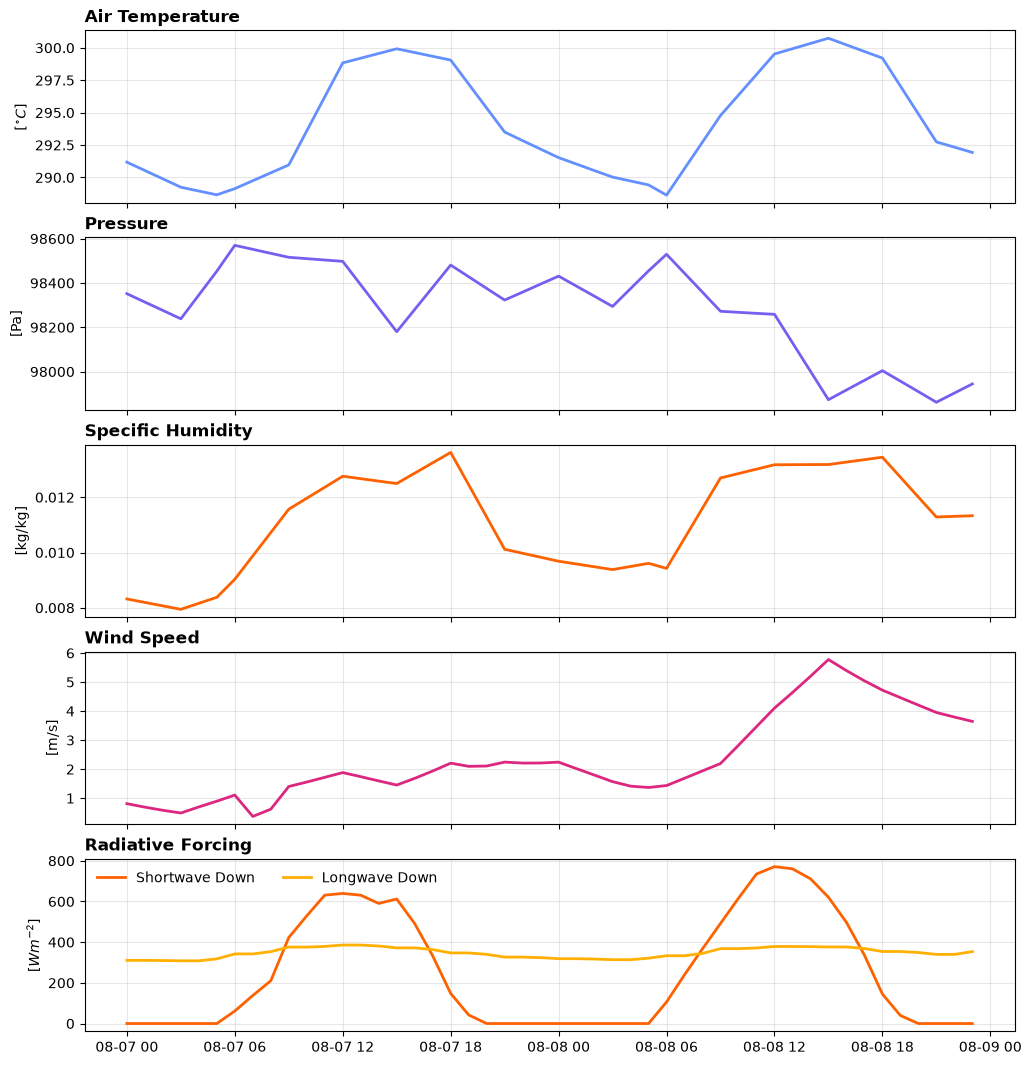

In [116]:
## Plot of the forcings
fig, axs = plt.subplots(5,1,figsize=(12,13), sharex=True)

STYLE = {
    "air_temp_forcing"    : (r'Air Temperature', r'[$^{\circ}C$]', IBM_BLUE, axs[0]),
    "pressure_forcing"    : ("Pressure", "[Pa]", IBM_PURPLE, axs[1]),
    "spechum_forcing"     : ("Specific Humidity", "[kg/kg]", IBM_ORANGE, axs[2]),
    "windsp_forcing"      : ("Wind Speed", "[m/s]", IBM_PINK, axs[3]),
    "swdn_forcing"        : (r'Shortwave Down', r'[$Wm^{-2}$]', IBM_ORANGE, axs[4]),
    "lwdn_forcing"        : (r'Longwave Down', r'[$Wm^{-2}$]', IBM_YELLOW, axs[4])
}

# now iterate over the dictionary and plot
for var, formatting in STYLE.items():
    ax = formatting[3]
    if var == 'swdn_forcing' or var == 'lwdn_forcing':
        label = formatting[0]
    else:
        label = ''
    ax.plot(hourly_data_combined['time_LST'], hourly_data_combined[var], c=formatting[2], lw=2, label=label)
    ax.set_ylabel(formatting[1])
    ax.grid(alpha=0.3)
    ax.set_title(formatting[0], loc='left', fontweight='bold')
    ax.legend(frameon=False, ncols=2)

# fix the radiative forcing axis
axs[4].set_title('Radiative Forcing', fontweight='bold', loc='left')

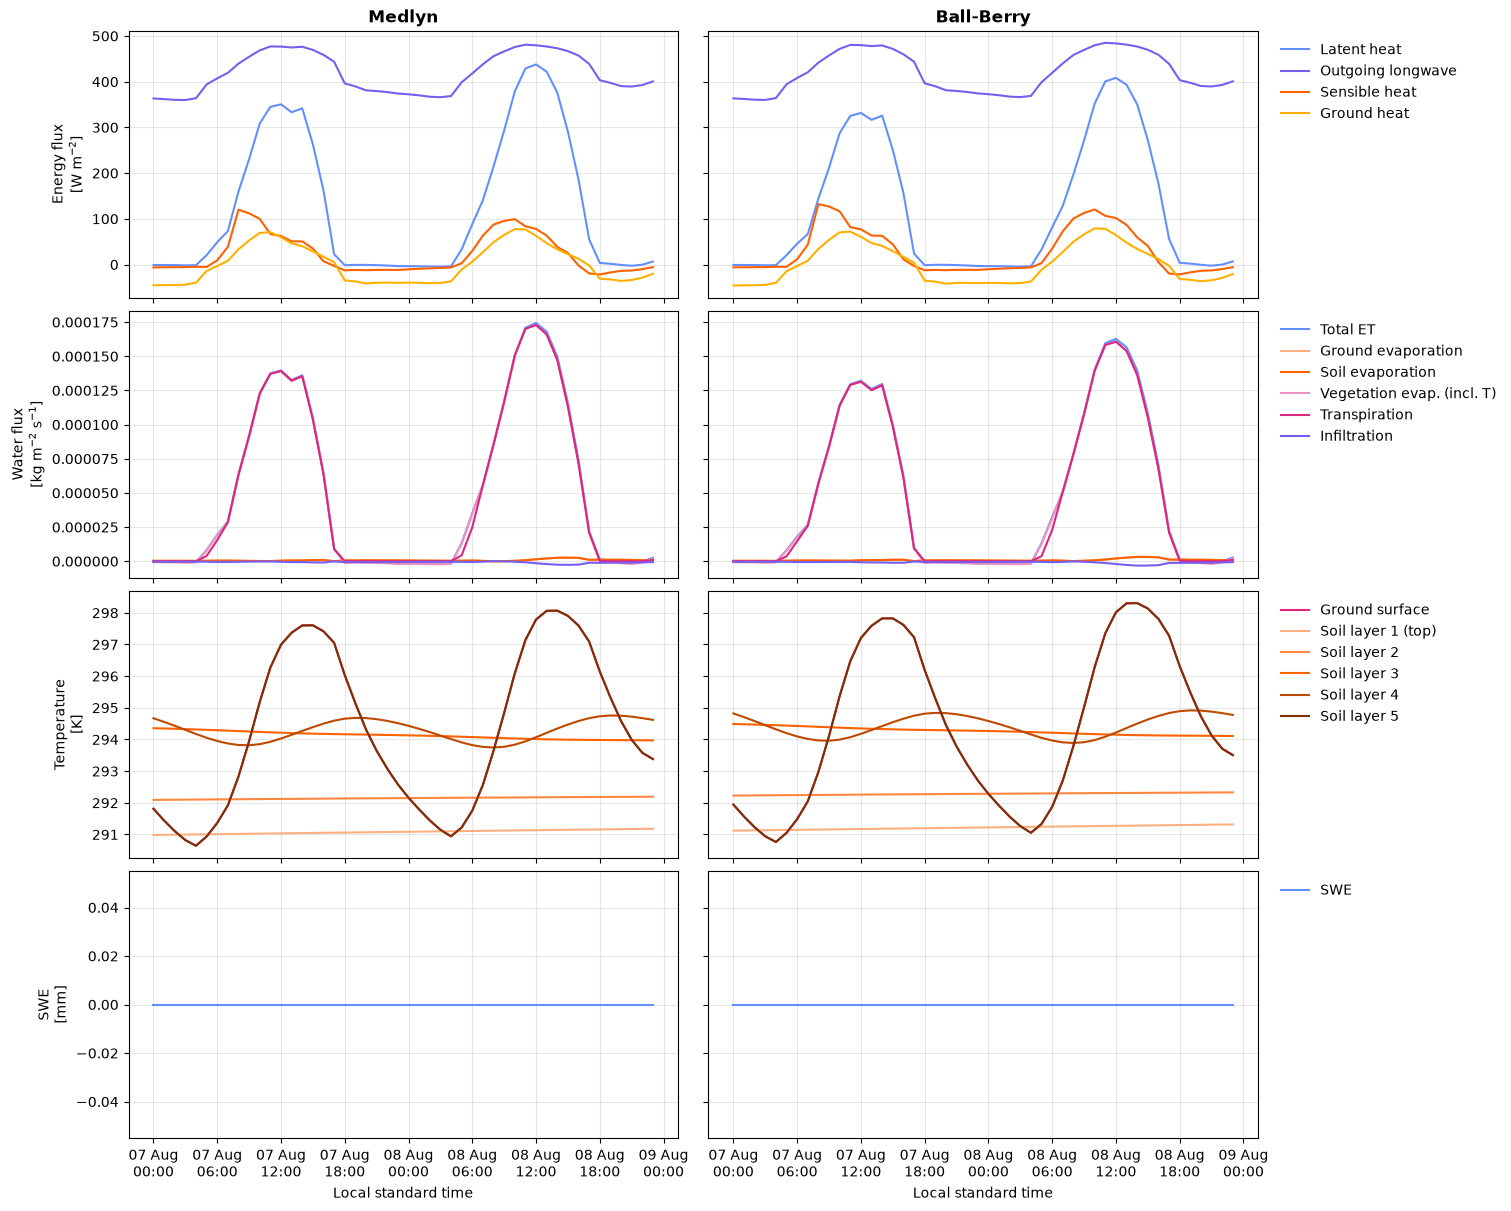

In [117]:
## ok - the plots for Q3.1 start here
def shade(hex_color, f):
    """Lighten (f > 0) or darken (f < 0) a color by blending it with white/black."""
    rgb = np.array(mcolors.to_rgb(hex_color))
    target = np.ones(3) if f > 0 else np.zeros(3)
    return mcolors.to_hex(rgb + abs(f) * (target - rgb))

# readable legend name and color for each output variable
# (variables not listed here fall back to their raw name in grey)
STYLE = {
    # energy fluxes
    "eflx_lh_tot"    : ("Latent heat",                 IBM_BLUE),
    "eflx_sh_tot"    : ("Sensible heat",               IBM_ORANGE),
    "eflx_lwrad_out" : ("Outgoing longwave",           IBM_PURPLE),
    "eflx_soil_grnd" : ("Ground heat",                 IBM_YELLOW),
    # water fluxes
    "qflx_evap_tot"  : ("Total ET",                    IBM_BLUE),
    "qflx_tran_veg"  : ("Transpiration",               IBM_PINK),
    "qflx_evap_veg"  : ("Vegetation evap. (incl. T)",  shade(IBM_PINK, 0.5)),
    "qflx_evap_soi"  : ("Soil evaporation",            IBM_ORANGE),
    "qflx_evap_grnd" : ("Ground evaporation",          shade(IBM_ORANGE, 0.5)),
    "qflx_infl"      : ("Infiltration",                IBM_PURPLE),
    # temperatures (soil layers are handled separately below)
    "t_grnd"         : ("Ground surface",              IBM_PINK),
    # snow
    "swe_out"        : ("SWE",                         IBM_BLUE),
}

# (prefix, y-label) for each row
groups = [
    ("eflx", "Energy flux\n[W m$^{-2}$]"),
    ("qflx", "Water flux\n[kg m$^{-2}$ s$^{-1}$]"),
    ("t_",   "Temperature\n[K]"),
    ("swe",  "SWE\n[mm]"),
]
models = [(clm_ds_medlyn, "Medlyn"), (clm_ds_ballberry, "Ball-Berry")]

fig, axs = plt.subplots(len(groups), len(models), figsize=(15, 12),
                        sharex=True, sharey="row", layout="constrained")

for j, (ds, name) in enumerate(models):          # j = column (model)
    axs[0, j].set_title(name, fontweight="bold")

    for i, (prefix, ylabel) in enumerate(groups):  # i = row (variable group)
        ax = axs[i, j]

        for v in ds.data_vars:
            if not v.startswith(prefix):
                continue
            da = ds[v].squeeze()

            # layered variables (t_soil): one line per layer, light = top, dark = deep
            if da.ndim > 1:
                layer_dim = [d for d in da.dims if d != "time"][0]
                n = da.sizes[layer_dim]
                for k in range(n):
                    ax.plot(ds["time"], da.isel({layer_dim: k}), lw=1.5,
                            color=shade(IBM_ORANGE, 0.5 - k / (n - 1)),
                            label=f"Soil layer {k + 1}" + (" (top)" if k == 0 else ""))

            # single-level variables: readable name and fixed color
            else:
                label, color = STYLE.get(v, (v, "0.5"))
                ax.plot(ds["time"], da, lw=1.5, color=color, label=label)

        ax.grid(alpha=0.3)
        if j == 0:
            ax.set_ylabel(ylabel)                  # y-label on left column only
        if j == len(models) - 1:                   # one legend per row, outside right
            ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)


for ax in axs[-1, :]:
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
    ax.set_xlabel("Local standard time")

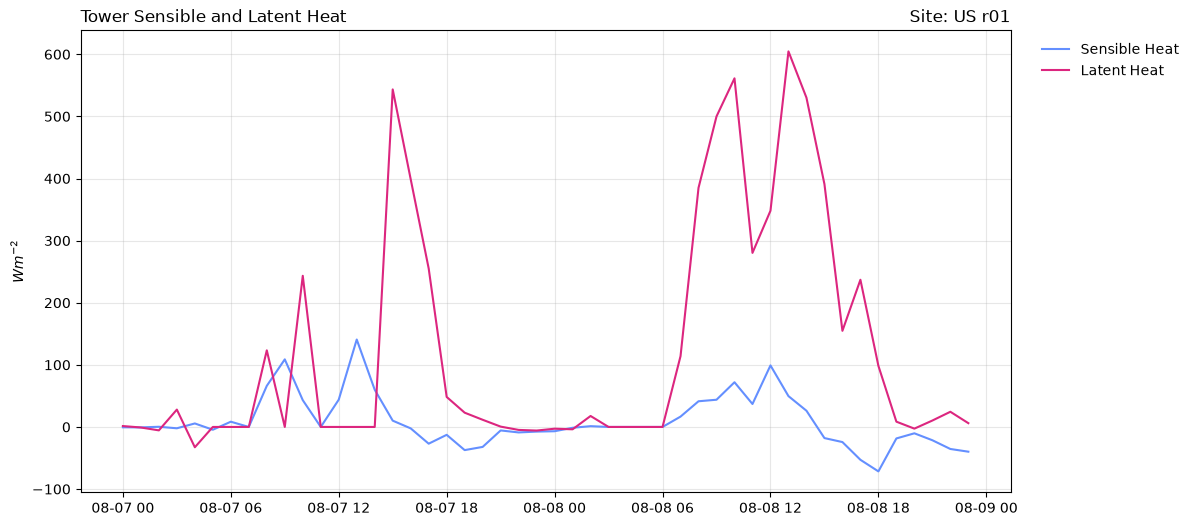

In [118]:
# plot the tower SH and LH
fig, ax = plt.subplots(1,1,figsize=(12,6))
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['tower_H'], c=IBM_BLUE, label='Sensible Heat')
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['tower_LE'], c=IBM_PINK, label='Latent Heat')
ax.grid(alpha=0.3)
ax.set_ylabel(r'$Wm^{-2}$')
ax.set_title('Tower Sensible and Latent Heat', loc='left')
ax.set_title('Site: US r01', loc='right')
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

17 panels


Text(0.5, 0.98, 'PF-CLM Runs for Selected Days')

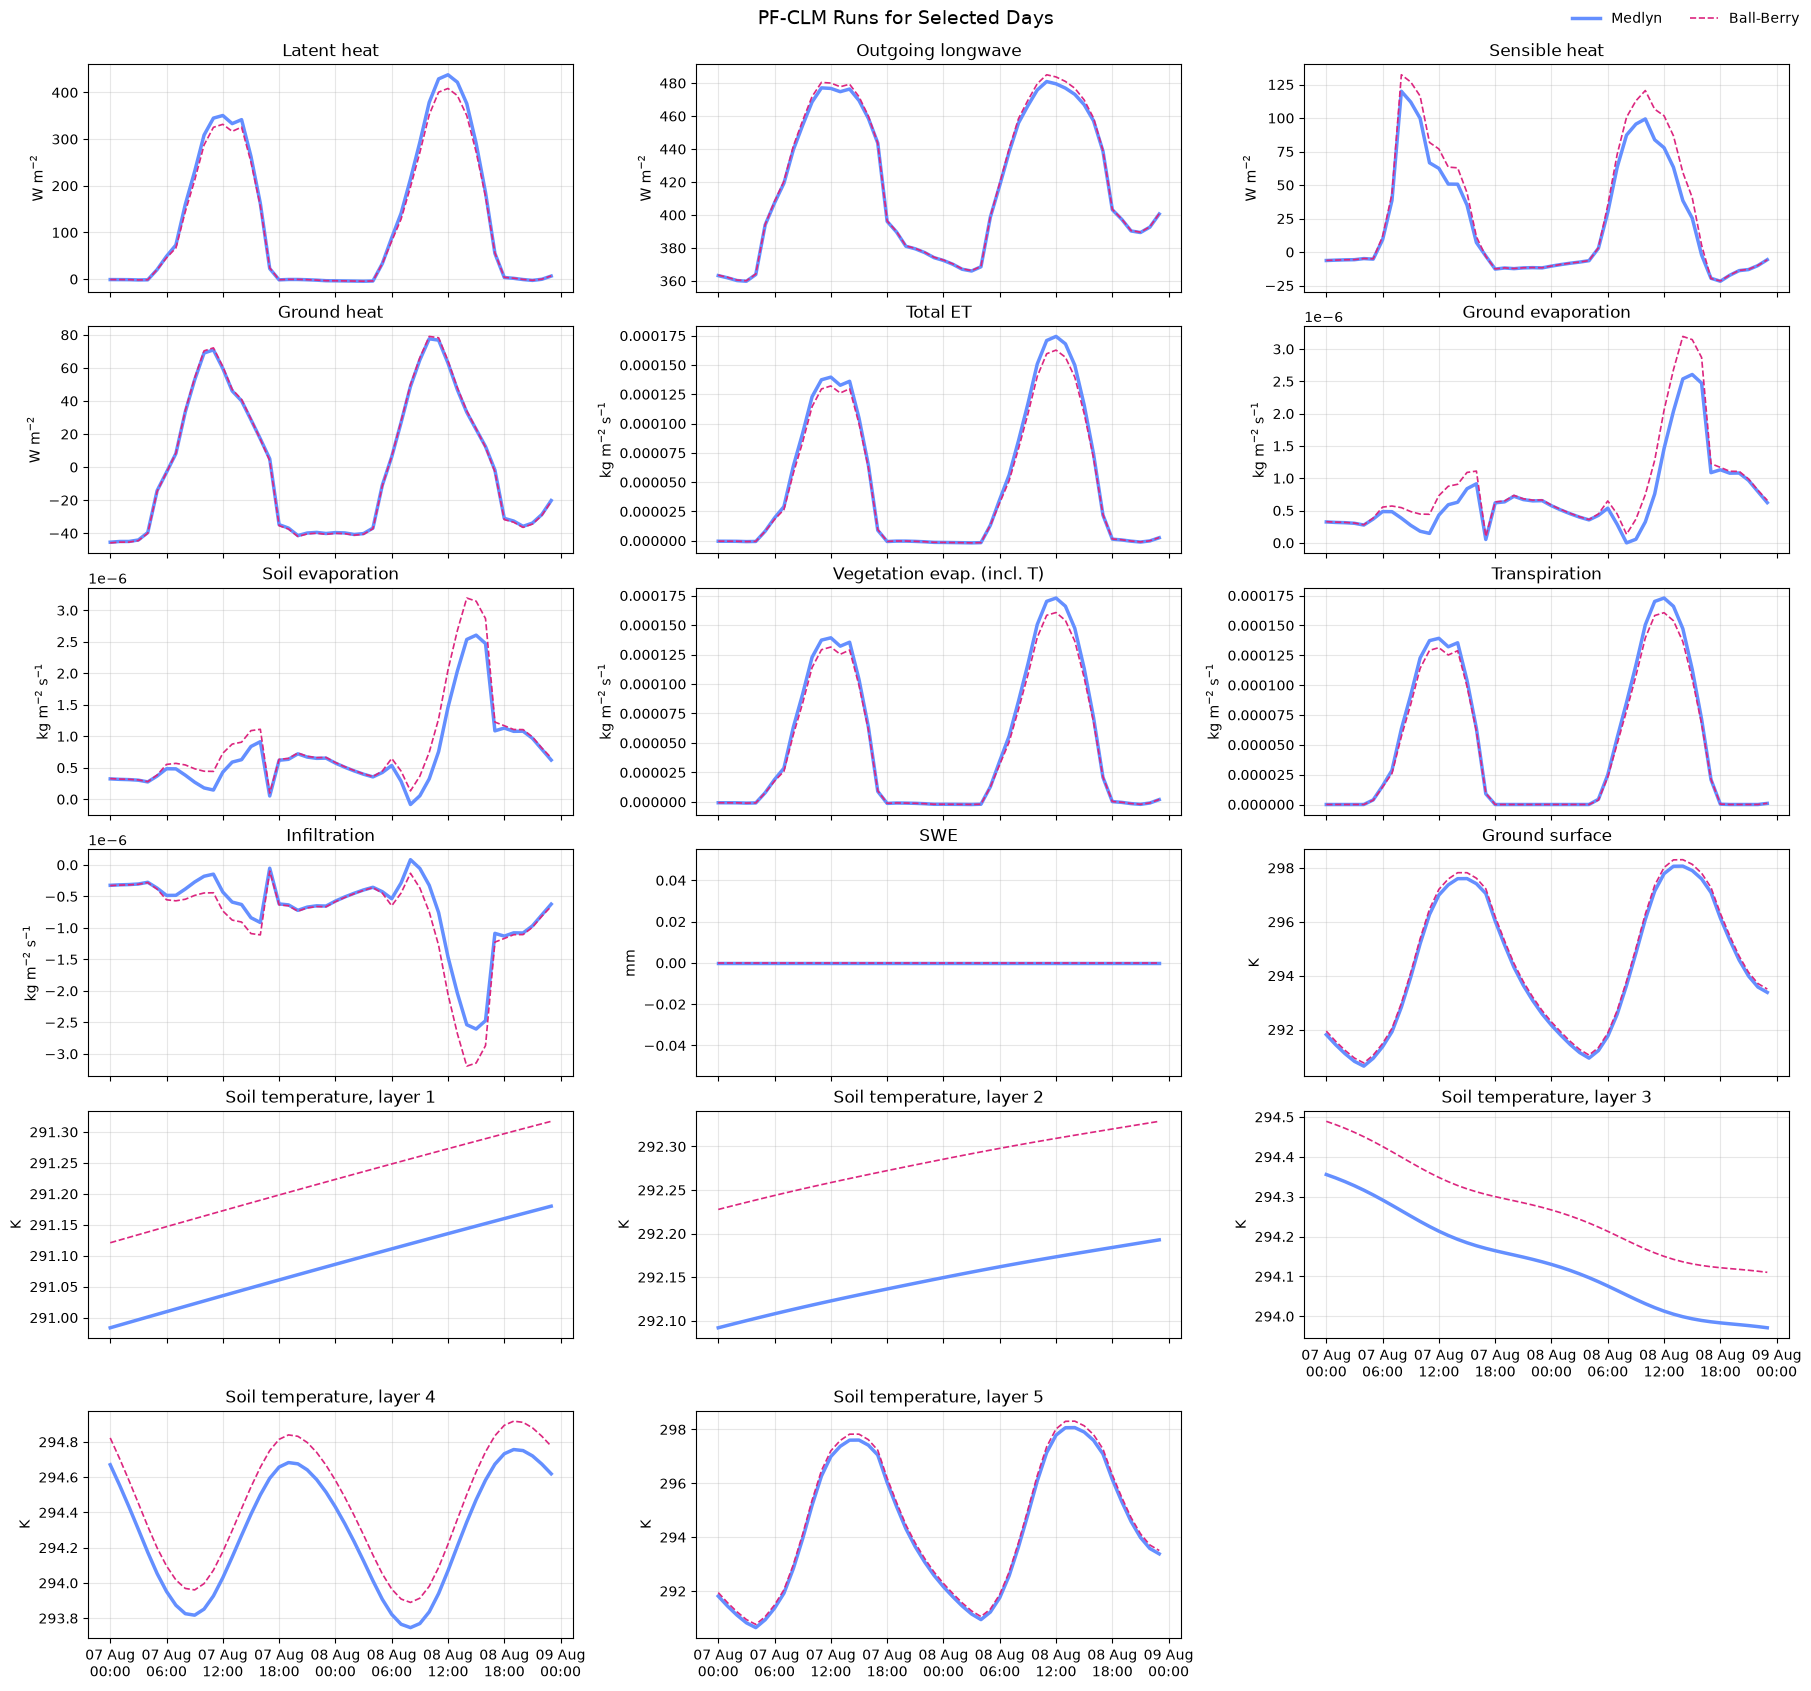

In [119]:
## Also plot all the different variables separately for each day
## NOTE: I did this one because Nyla and I were confused over bad LH fluxes that turned out to be 
## a result of the water table depth being too shallow (reference to the table)


# units by variable prefix (used for the y-labels)
UNITS = {
    "eflx": "W m$^{-2}$",
    "qflx": "kg m$^{-2}$ s$^{-1}$",
    "t_"  : "K",
    "swe" : "mm",
}

def unit_of(v):
    """Return the unit string for a variable based on its prefix."""
    for prefix, unit in UNITS.items():
        if v.startswith(prefix):
            return unit
    return ""

STYLE["t_soil"] = ("Soil temperature", IBM_ORANGE)   # readable name for the layered variable

# build one panel per variable (one per layer for layered variables)
panels = []
for v in clm_ds_medlyn.data_vars:
    if v not in clm_ds_ballberry:
        continue
    med  = clm_ds_medlyn[v].squeeze()
    bb   = clm_ds_ballberry[v].squeeze()
    name = STYLE.get(v, (v, None))[0]

    if med.ndim > 1:
        layer_dim = [d for d in med.dims if d != "time"][0]
        for k in range(med.sizes[layer_dim]):
            panels.append((f"{name}, layer {k + 1}", unit_of(v),
                           med.isel({layer_dim: k}), bb.isel({layer_dim: k})))
    else:
        panels.append((name, unit_of(v), med, bb))

print(f"{len(panels)} panels")   # check before plotting

# grid of subplots, 3 per row
ncols = 3
nrows = int(np.ceil(len(panels) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(18, 2.8 * nrows),
                        sharex=True, layout="constrained")
axs = axs.ravel()

for ax, (title, unit, med, bb) in zip(axs, panels):
    # Medlyn wide and solid, Ball-Berry thin and dashed, so overlap stays visible
    ax.plot(med["time"], med, color=IBM_BLUE, lw=2.5, label="Medlyn")
    ax.plot(bb["time"],  bb,  color=IBM_PINK, lw=1.2, ls="--", label="Ball-Berry")

    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.grid(alpha=0.3)

# hide unused axes and restore x tick labels on the axes above them
for idx in range(len(panels), len(axs)):
    axs[idx].set_visible(False)
    axs[idx - ncols].xaxis.set_tick_params(labelbottom=True)

# readable time axis (shared, so set once)
axs[0].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))

# one legend for the whole figure
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper right",
           ncols=2, frameon=False)

fig.suptitle('PF-CLM Runs for Selected Days', fontsize=14)

### 3.2 Potential Evaporation, Hourly
Choose one method: (a) mean variables (bulk transfer) under neutral conditions, or (b) Penman. Write is as a Python function that takes a table of hourly inputs and returns latent heat in $Wm^{-2}$. Both methods use the same aerodynamic resistance, $r_a$.

In [120]:
# combination approaches
# DEFINE CONSTANTS
lam_v = 2.45e6   # [Jkg^-1]
c_p = 1005.0     # [Jkg^-1k^-1]
k = 0.4

# pull out the data for aerodynamics from the config files (copied and pasted)
z0m_arr = [1.00,2.20,1.00,0.80,0.80,0.10,0.10,0.70,0.10,0.03,0.03,0.06,0.50,0.06,0.01,0.05,0.002,0.01]
displa_arr = [11.0,23.00,11.0,13.0,13.0,0.30,0.30,6.50,0.70,0.30,0.30,0.30,3.00,0.30,0.00,0.10,0.00,0.00]
IGBP_NO = 12 - 1  # from locate station (I assume .dat is for FORTRAN so need to use 0-based idx instead)

z0m_stn = z0m_arr[IGBP_NO]        # [m]
displa_stn = displa_arr[IGBP_NO]  # [m]

def E_penman(P, T_a, q, u, Rn_minus_G, 
            z0m=z0m_stn, d_0=displa_stn, 
            c_p = c_p, lam_v = lam_v, k = k, z = 30):
    r"""
    Function calculates the evaporation using Penman. 

    From tips and tricks: 
        $\lambda E = [Δ (Rn - G) + \rho cp (es(Ta) - ea) / ra] / (Δ + \gamma)$
        $ra = ln[(z - d_o)/z_o m] ln[(z - d_o)/z_ov] / (k^{2} u)$

    Parameters
    ----------
    P : float
        air pressure [Pa]
    T_a : float
        air temperature [K]
    q : float
        specific humidity [kg/kg]
    u : float
        wind speed [ms^-1]
    Rn_minus_G : float 
        Available energy [Wm^-2]
    z0m : float
        roughness length for ths station [m]
    d_0 : float
        displacement height at the station [m]
    c_p : float 
        specific heat capacity of dry air [Jkg^-1K^-1]
    lam_v : float
        latent heat of vaporization of water [Jkg^-1]
    k : float
        von-karman constant [unitless]
    z : float
        forcing height [m]
    """
    # find air density [kg/m^3]
    rho = P / (287 * T_a)

    # find saturation vapor pressure [Pa]
    T_ac = T_a - 273.15
    e_s = 611.2 * np.exp((17.67 * T_ac) / (T_ac + 243.5))

    # find actual vapor pressure [Pa]
    e_a = (q * P) / (0.622 + (0.378 * q))

    # find slope of the saturation vapor pressure [Pak^-1]
    Delta = 17.67 * 243.5 * (e_s/(T_ac + 243.5)**2)

    # find the psychometric constant [Pak^-1]
    gamma = (c_p * P) / (0.622 * lam_v)

    # find the vapor roughness length [m]
    z0v = z0m / 10 

    # find the aerodynamic resistance
    r_a = (np.log((z - d_0) / (z0m)) * np.log((z - d_0) / z0v))/(k**2 * u)
    print(f"Sanity Check: mean r_a: {np.mean(r_a)} s/m")

    # finally, compute the latent heat
    LE = (Delta * Rn_minus_G + (rho * c_p * (e_s - e_a))/r_a) / (Delta + gamma)
    return LE

def E_penman_from_df(hourly_data_combined, temp_var='air_temp_forcing'):
    """
    Wrapper for the E_penman function so that just
    a dataframe can be passed in while keeping the 
    actual math in the function more traceable to debug
    because I messed something up at first...

    Parameters
    ----------
    data_combined : pd.DataFrame
        pandas dataframe containing all the forcing data
        as given in the tips and tricks section

    Returns
    -------
    LE_results : dict
        dictionary containing the latent heat for
        Medlyn, Ball-Berry and with the Rn - G from the two averaged
    """ 
    # as in tips and tricks
    Rn_minus_G_med =  hourly_data_combined['pfclm_lh_tot_med'] + hourly_data_combined['pfclm_sh_tot_med']
    Rn_minus_G_bb =  hourly_data_combined['pfclm_lh_tot_bb'] + hourly_data_combined['pfclm_sh_tot_bb']
    Rn_minus_G_avg = (Rn_minus_G_med + Rn_minus_G_bb) / 2

    LE_Medlyn = E_penman(
        P = hourly_data_combined['pressure_forcing'],
        T_a = hourly_data_combined[temp_var],
        q = hourly_data_combined['spechum_forcing'],
        u = hourly_data_combined['windsp_forcing'],
        Rn_minus_G = Rn_minus_G_med
    )

    LE_BallBerry = E_penman(
        P = hourly_data_combined['pressure_forcing'],
        T_a = hourly_data_combined[temp_var],
        q = hourly_data_combined['spechum_forcing'],
        u = hourly_data_combined['windsp_forcing'],
        Rn_minus_G = Rn_minus_G_bb
    )

    LE_avg = E_penman(
        P = hourly_data_combined['pressure_forcing'],
        T_a = hourly_data_combined[temp_var],
        q = hourly_data_combined['spechum_forcing'],
        u = hourly_data_combined['windsp_forcing'],
        Rn_minus_G = Rn_minus_G_avg
    )

    LE_results = {
        'time_LST' : hourly_data_combined['time_LST'],
        'LE_Medlyn' : LE_Medlyn,
        'LE_BallBerry' : LE_BallBerry,
        'LE_Avg' : LE_avg
    }

    return LE_results

In [121]:
LE_df_q32 = pd.DataFrame(E_penman_from_df(hourly_data_combined))
# print the midday hours 
print('')
print(LE_df_q32[LE_df_q32['time_LST'] == '2016-08-07 12:00:00'])
print(LE_df_q32[LE_df_q32['time_LST'] == '2016-08-08 12:00:00'])
print('')

Sanity Check: mean r_a: 216.7324284282083 s/m
Sanity Check: mean r_a: 216.7324284282083 s/m
Sanity Check: mean r_a: 216.7324284282083 s/m

              time_LST   LE_Medlyn  LE_BallBerry      LE_Avg
12 2016-08-07 12:00:00  342.831459    339.560931  341.196195
              time_LST   LE_Medlyn  LE_BallBerry      LE_Avg
36 2016-08-08 12:00:00  464.064081    459.893329  461.978705



In [122]:
# read in mass transfer
MT_df_q32 = pd.read_csv("/workspaces/single_column_PFCLM/runs/et/mass_transfer_LE_timeseries.csv")
MT_df_q32['Time'] = pd.to_datetime(MT_df_q32['Time'])
MT_df_q32.head()

,Time,Medlyn_MassTransfer_LE,BallBerry_MassTransfer_LE
0,2016-08-07 00:00:00,37.482519,38.275165
1,2016-08-07 01:00:00,30.867683,31.511531
2,2016-08-07 02:00:00,25.333092,25.853915
3,2016-08-07 03:00:00,20.929741,21.352757
4,2016-08-07 04:00:00,27.548223,28.133081


##### By hand: Pick one midday hour and compute your method on paper. Show every term with its units and report your $r_a$ for that hour in $sm^-1$. Check it against your function. If they differ find out why.

Attached in the PDF with all by hand answers. I included the original calculation before Louisa told us about the deeper water table from Table 2 of Maxwell (2026), which we then adjusted, alongside the calculation with the new forcings to show that regardless of this, it works out as expected and also because I think it answers my question from the paper review about the water table depth well.

##### Compare both methods to the tower latent heat and to the two PF-CLM runs: one figure, hourly, all five series

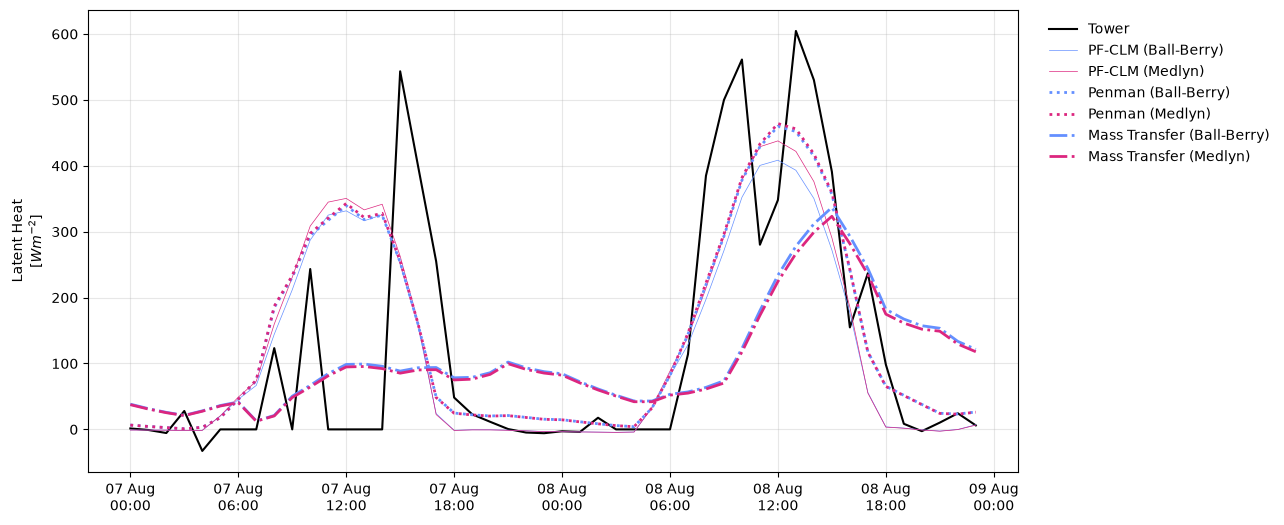

In [123]:
# compare both methods to the tower latent heat and to the two PF-CLM runs: one figure, hourly, all five series
fig, ax = plt.subplots(1, 1, figsize=(12,6))

# first plot the tower latent heat
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['tower_LE'], label='Tower', c='k')
# next plot the two parflow clm runs
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['pfclm_lh_tot_bb'], lw=0.5, label='PF-CLM (Ball-Berry)', c=IBM_BLUE)
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['pfclm_lh_tot_med'], lw=0.5, label='PF-CLM (Medlyn)', c=IBM_PINK)
# next plot the penman versions
ax.plot(LE_df_q32['time_LST'], LE_df_q32['LE_BallBerry'], label='Penman (Ball-Berry)', c=IBM_BLUE, ls=':', lw=2)
ax.plot(LE_df_q32['time_LST'], LE_df_q32['LE_Medlyn'], label='Penman (Medlyn)', c=IBM_PINK, ls=':', lw=2)
#ax.plot(LE_df_q32['time_LST'], LE_df_q32['LE_Avg'], label=r'Penman (Average PF-CLM $R_n - G$)', c=IBM_PURPLE, ls=':', lw=2)
# finally plot the mass transfer version
ax.plot(MT_df_q32['Time'], MT_df_q32['BallBerry_MassTransfer_LE'], label='Mass Transfer (Ball-Berry)', c=IBM_BLUE, ls='-.', lw=2)
ax.plot(MT_df_q32['Time'], MT_df_q32['Medlyn_MassTransfer_LE'], label='Mass Transfer (Medlyn)', c=IBM_PINK, ls='-.', lw=2)

ax.grid(alpha=0.3)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))

ax.set_ylabel('Latent Heat\n' + r'[$Wm^{-2}$]')

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

##### With your partner, write one shared paragraph comparing the two methods at your two sites. Where do they agree, where do they differ and why?
We computed mean variables derived and Penman derived latent heat for both Medlyn and Ball-Berry stomatal schemes. Both the penman and mean variables values exhibit diurnal behavior. However, Penman incorporates both energy and water limitations, whereas mean variables relies only on specific humidity considerations. In an environment where water is more limited than energy, such as in this case where the site is modeled mid-summer with a relatively deep water table depth (1.6 meters), the Penman formulation will incorporate additional latent heat flux from the massive incoming radiation to the system. For this reason, the magnitude of mass transfer is lower than Penman during the middle of the day, but is larger than Penman over night-time when incoming radiation drops. Moreover, during the night the Penman approach shuts off completely because energy goes to zero, but the mass transfer approach does allow for some latent heat release during the night (representative of bare soil evaporation since ET will shut off due to stomatal closure) if the high water table allows a large vertical specific humidity gradient (vapor pressure deficit) to persist. There is also a lag in the peaks of mean variables compared with Penman. This makes sense because the specific humidity difference drives the magnitude of the mass transfer approach, and ground temperatures, which directly affect the soil specific humidity, peak in the early afternoon. Therefore, unlike Penman which is dominated by energy fluxes that peak mid-day, the mean variables latent heat peaks slightly later.

### 3.3 - Stability
##### write Brutseart 2.11 as a Python function: given wind speed, height, roughness, displacement 

Textbook question: During a field expeirment above a grassy surface, the following mean values were measured over a 1 h period: the tempeature at 1.5 m above the ground, $T_{1.5} = 31.29^{\circ}C$; at 3.0 m above the ground $T_3 = 30.87 ^{\circ}C$; and the wind speed at 2.0 m, $u = 3$  m/s. The surface roughness was estimated to be $z_0 = 0.01$ m and the displacement height, $d_0$ was foudn to be negligable. 
* a) calculate, by iteration, the friction velocity $u_{*}$, and the sensible heat flux, H. The evaporation term $\overline{w'q'}$ in L can be assumed negligable. 
* b) If the net radiation is $R_n$ = 392 Wm^-2, calculate the rate of evaporation from $L_eE = R_n - H$ first in W/m^2 and then in mm/month

In [ ]:
# write Brutseart 2.11 as a Python function: given wind speed, height, roughness, displacement and sensible heat flux, iterature u* and L to convergence and 
# return \zeta \psi_m, \psi_v and the stability corrected r_a

def monin_obukhov_b211(u, z, d0, H, T, z0m, rho=1.2, k=0.4, g=9.81, c_p =1005, niters=10, clip_zeta = True):
    """
    Function computes the variables requested in Brutseart 2.11
    using MOST to apply stability corrections, following the tips
    and tricks final bullet point from the HW.

    Parameters
    ----------
    u : float
        wind speed [m/s]
    z : float
        measurement height [m]
    d0 : float
        displacement height [m]
    H : float
        sensible heat flux [wm^-2]
    T : float
        temperature [K]
    z0m : float
        roughness length [m]
    k : float
        von-karman constant [unitless]
    g : float
        gravity [m/s^2]
    c_p : float
        specific heat of air [Jkg^-1K^-1]
    niters : int
        number of iterations to do to converge u*

    Returns
    -------
    zeta : float
        stability ratio [unitless ratio]
    psi_m : float
        integrated stability correction function [unitless]
    psi_v : float
        integrated vapor correction function [unitless]
    ra_corr : float
        stability corrected roughness length [m]
    """
    # skip hours where |H| is less than 10Wm^-2
    if np.abs(H) < 10:
        return np.nan, np.nan, np.nan, np.nan, np.nan

    # start at neutral
    psi_m, psi_v = 0, 0

    # from tips and tricks
    z0v = z0m / 10

    for i in range(niters):
        # compute the friction velocity
        u_star = (k * u) / (np.log((z - d0)/ z0m) - psi_m)

        # compute a first guess of the obukhov length
        L = (-1 * rho * c_p * T * u_star**3) / (k * g * H)

        # compute the stability ratio
        zeta = (z-d0) / L
        #print(f'DEBUG: zeta pre-clip = {zeta}')
        if clip_zeta:
            zeta = np.clip(zeta, -2, 1) # force it to stay between -2 and 1

        # now check the stability condition and calculate the corrections
        if zeta > 0:
            # stable conditions
            psi_m = psi_v = -5 * zeta
        elif zeta < 0:
            # unstable conditions
            # compute x
            x = (1 - (16 * zeta))**(1/4)
            psi_m = 2 * np.log((1 + x) / 2) + np.log((1 + x**2) / 2) - 2 * np.arctan(x) + (np.pi / 2)
            psi_v = 2 * np.log((1 + x**2) / 2)
        elif zeta == 0:
            # neutral conditions
            psi_m = psi_v = 0.0
        # compute r_a
        ra_corr = ((np.log((z - d0)/ z0m) - psi_m) * (np.log((z - d0) / z0v) - psi_v)) / (k**2 * u)
        

    return zeta, psi_m, psi_v, ra_corr, u_star   

In [165]:
# now solve the Brutseart question - note that i think you cant write this
# as a function and also have the function do what the question asks you
# to return, and it would make everything else break. I know in OH we discussed
# needing to do the question then reuse teh function, so I kept the function in
# the reusable form I had it and then solved the rest outside

# we cant convert to potential temperature because we dont have a pressure
# but we can follow Brutseart's statement that near the surface the potential
# and actual temperatures are close enough to just use that
u, z_u = 3.0, 2.0 
z1, z2 = 1.5, 3.0 
T1, T2 = 31.29, 30.87 
z0m, d0 = 0.01, 0.0
T_K = 273.15 + (T1 + T2) / 2  # take an average bc the function allows 1 level only
rho, c_p, k, g = 1.16, 1005, 0.4, 9.81

# 
def psi_h(zeta):
    """
    just do psi_h the same as psi_v because i couldnt
    figure out another way from the textbook even and though
    I dont think they are actually the same in practice we dont
    have the heat roughness length and i think since it is molecular
    diffusion it should be similar to water?
    """
    if zeta >= 0:
        return -5 * zeta          
    x2 = np.sqrt(1 - 16 * zeta)   
    return 2 * np.log((1 + x2) / 2)      


u_star = k * u / np.log(z_u / z0m)
H = -rho * c_p * k * u_star * (T2 - T1) / np.log(z2 / z1)
print(f"neutral: u*={u_star:.4f} m/s, H={H:.1f} W/m2")

for i in range(10):
    zeta, psi_m, psi_v, ra, u_star = monin_obukhov_b211(
        u, z_u, d0, H, T_K, z0m, rho=rho, niters=50)
    L = -rho * c_p * T_K * u_star**3 / (k * g * H)
    H_new = (-rho * c_p * k * u_star * (T2 - T1)
             / (np.log(z2 / z1) - psi_h(z2 / L) + psi_h(z1 / L)))
    print(f"iter {i}: u*={u_star:.4f}, L={L:.2f} m, H={H_new:.1f}")
    
    H = H_new
H = H_new


LE = 392 - H                                 
lam = 2.501e6 - 2361 * (T_K - 273.15)        
E = LE / lam                                 
print(f"LE = {LE:.1f} W/m2, E = {E*86400:.2f} mm/day = {E*86400*30:.0f} mm/month")


neutral: u*=0.2265 m/s, H=64.0 W/m2
iter 0: u*=0.2396, L=-19.43 m, H=112.2
iter 1: u*=0.2455, L=-11.92 m, H=136.0
iter 2: u*=0.2479, L=-10.13 m, H=145.9
iter 3: u*=0.2488, L=-9.54 m, H=149.9
iter 4: u*=0.2492, L=-9.33 m, H=151.4
iter 5: u*=0.2493, L=-9.25 m, H=152.0
iter 6: u*=0.2494, L=-9.22 m, H=152.2
iter 7: u*=0.2494, L=-9.21 m, H=152.3
iter 8: u*=0.2494, L=-9.20 m, H=152.4
iter 9: u*=0.2494, L=-9.20 m, H=152.4
LE = 239.6 W/m2, E = 8.53 mm/day = 256 mm/month


Plot the ratio of neutral to stability-corrected $r_a$ against $zeta$ from -2 to +1

for the question below I think I need to cancel variables to prove the ratio doesn't end up depending on the meteorological variables?

From tips and tricks: $z0v = z0m / 10$

for neutral conditions:
$$
r_{a,n} = \frac{ln(\frac{z - d_0}{z0m})ln(\frac{z - d_0}{0.1 \cdot z0m})}{k^{2}u}
$$

with stability correction:
$$
r_{a,corr} = \frac{(ln(\frac{z - d_0}{z0m}) - \psi_m)(ln(\frac{z - d_0}{0.1 \cdot z0m}) - \psi_v)}{k^{2}u}
$$

so taking the ratio:

$$
\frac{r_{a,n}}{r_{a,corr}} = \frac{[\frac{ln(\frac{z - d_0}{z0m})ln(\frac{z - d_0}{0.1 \cdot z0m})}{k^{2}u}]}{[\frac{(ln(\frac{z - d_0}{z0m}) - \psi_m)(ln(\frac{z - d_0}{0.1 \cdot z0m}) - \psi_v)}{k^{2}u}]}
$$

then simplifying:

$$
\frac{r_{a,n}}{r_{a,corr}} = \frac{ln(\frac{z-d_0}{z0m}) \cdot ln(\frac{z - d_0}{0.1 \cdot z0m})}{[ln(\frac{z - d_0}{z0m}) - \psi_m][ln(\frac{z - d_0}{0.1 \cdot z0m}) - \psi_v]}
$$

Text(1.0, 1.0, 'Station: US r01\nz0m: 0.06m, d0: 0.3m')

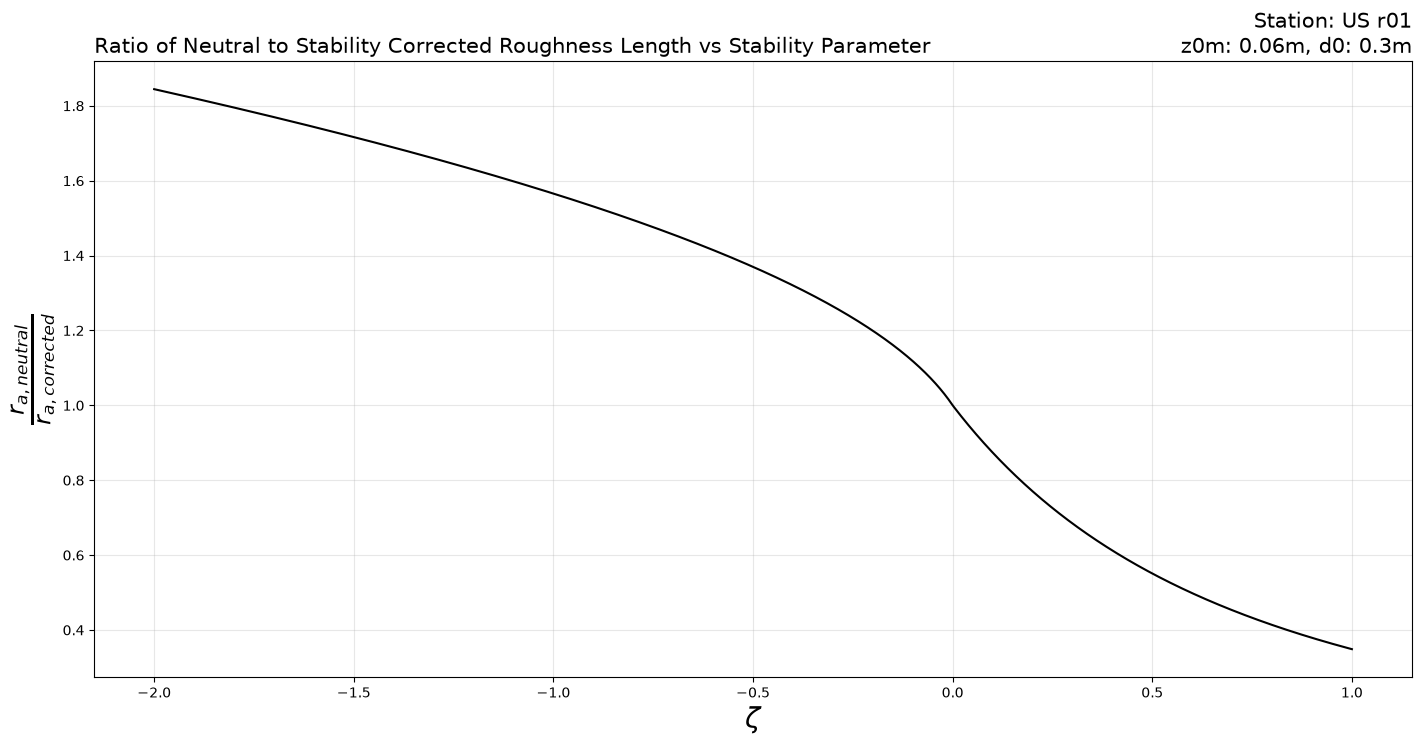

In [126]:
# plot the ratio of neutral to stability-corrected r_a against zeta from -2 to +1
zeta_arr = np.linspace(-2, 1, 5000)

ratio_arr = []

z0m_arr = [1.00,2.20,1.00,0.80,0.80,0.10,0.10,0.70,0.10,0.03,0.03,0.06,0.50,0.06,0.01,0.05,0.002,0.01]
displa_arr = [11.0,23.00,11.0,13.0,13.0,0.30,0.30,6.50,0.70,0.30,0.30,0.30,3.00,0.30,0.00,0.10,0.00,0.00]

# this is for my station
IGBP_NO = 12 - 1  # from locate station (I assume .dat is for FORTRAN so need to use 0-based idx instead)
z0m_stn = z0m_arr[IGBP_NO]        # [m]
d0_stn = displa_arr[IGBP_NO]  # [m]

# now loop over the zeta values and find the stability corrected and neutral r_a
def compute_ratio(zta, z0m_stn, d0_stn, z):
    if zta > 0:
            # stable conditions
            psi_m = psi_v = -5 * zta
    elif zta < 0:
        # unstable conditions
        # compute x
        x = (1 - (16 * zta))**(1/4)
        psi_m = 2 * np.log((1 + x) / 2) + np.log((1 + x**2) / 2) - 2 * np.arctan(x) + (np.pi / 2)
        psi_v = 2 * np.log((1 + x**2) / 2)
    elif zta == 0:
        # neutral conditions
        psi_m = psi_v = 0.0

    # now compute the ratio
    numer = (np.log((z - d0_stn) / (z0m_stn)) * np.log((z - d0_stn) / (0.1 * z0m_stn)))
    denom = ((np.log((z-d0_stn) / z0m_stn) - psi_m) * (np.log((z-d0_stn) / (0.1 * z0m_stn)) - psi_v))
    
    #ratio = (np.log((z - d0_stn) / (z0m_stn)) * np.log((z - d0_stn) / (0.1 * z0m_stn))) / ((np.log((z-d0_stn) / z0m_stn) - psi_m) * (np.log((z-d0_stn) / (0.1 * z0m_stn)) - psi_v))
    return numer / denom
        

# now loop over all the zetas for us r01
for zt in zeta_arr:
    ratio = compute_ratio(zt, z0m_stn, d0_stn, 30)         
    ratio_arr.append(ratio)

# now plot
fig, ax = plt.subplots(1,1,figsize=(17,8))
ax.plot(zeta_arr, ratio_arr, c='k')
ax.set_xlabel(r'$\zeta$', fontsize=20)
ax.set_ylabel(r'$\frac{r_{a,neutral}}{r_{a,corrected}}$', fontsize=25)

ax.grid(alpha=0.3)

ax.set_title('Ratio of Neutral to Stability Corrected Roughness Length vs Stability Parameter', loc='left', fontsize=15)
ax.set_title(f'Station: US r01\nz0m: {z0m_stn}m, d0: {d0_stn}m', loc='right', fontsize=15)

(0.0, 2.0)

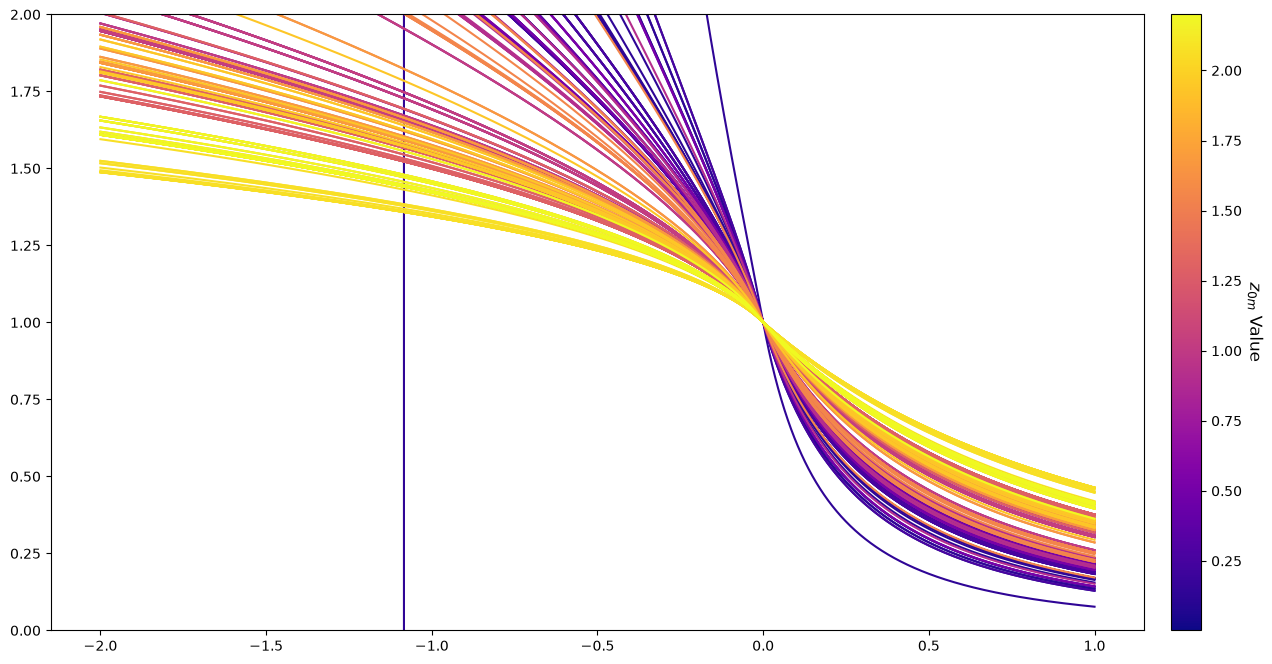

In [127]:
# SANITY CHECK: as in question, should be the same at every station
fig, ax = plt.subplots(1, 1, figsize=(17, 8))

cmap_name = 'plasma'
cmap = plt.colormaps[cmap_name]

z0_min = min(z0m_arr)
z0_max = max(z0m_arr)

colors = cmap(np.linspace(0, 1, len(z0m_arr)))

for i, z0 in enumerate(z0m_arr):
    line_color = colors[i] 
    
    for d0 in displa_arr:
        ratios_arr = []
        for zt in zeta_arr:
            ratio = compute_ratio(zt, z0, d0, 30) 
            ratios_arr.append(ratio)      

        ax.plot(zeta_arr, ratios_arr, c=line_color)


norm = plt.Normalize(vmin=z0_min, vmax=z0_max)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([]) # Required for older matplotlib compatibility

# 4. Append the colorbar to the figure and label it
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('$z_{0m}$ Value', rotation=270, labelpad=15, fontsize=12) 
ax.set_ylim(0,2)

Pick three hours from your two days: one at night, one in mid-morning, and the hour of peak sensible heat. Compute $\zeta$ for rach from your tower's observed H and wind, and mark them on the curve. Say whether each hour is stable or unstable, and which statements from Brusteart 2.1 and 2.2 explain it.

In [128]:
hourly_data_combined[hourly_data_combined.tower_H == hourly_data_combined.tower_H.max()]['time_LST'].squeeze().strftime('%Y-%m-%d %H:%M:%S')

'2016-08-07 13:00:00'

Night: zeta: 1.0, H: -32.14, ra_corr : 2667.36, ratio : 0.35, psi_m: -5.00, psi_v: -5.00
Mid-Morning: zeta: -2.0, H: 43.82, ra_corr : 88.21, ratio : 1.84, psi_m: 1.49, psi_v: 2.43
Peak H: zeta: -2.0, H: 140.75, ra_corr : 128.26, ratio : 1.84, psi_m: 1.49, psi_v: 2.43


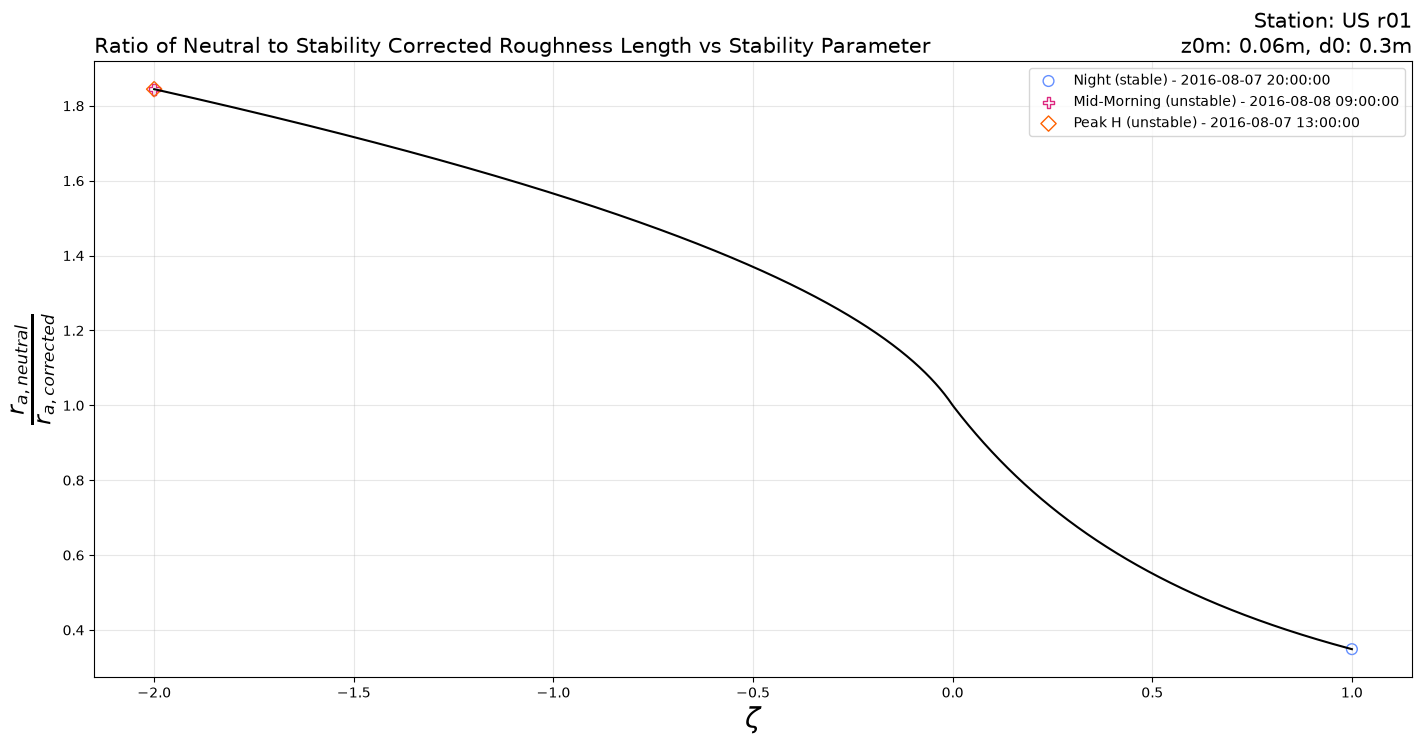

In [129]:
# Pick three hours from your two days: one at night, one in mid-morning, and the hour of peak
# sensible heat. Compute ζ for each from your tower's observed H and wind, and mark them on
# the curve. Say whether each hour is stable or unstable, and which statements from Brutsaert
# plot the ratio of neutral to stability-corrected r_a against zeta from -2 to +1

# re-plot the curve
zeta_arr = np.linspace(-2, 1, 5000)

ratio_arr = []

# now loop over all the zetas for us r01
for zt in zeta_arr:
    ratio = compute_ratio(zt, z0m_stn, d0_stn, 30)         
    ratio_arr.append(ratio)

# now plot
fig, ax = plt.subplots(1,1,figsize=(17,8))
ax.plot(zeta_arr, ratio_arr, c='k')
ax.set_xlabel(r'$\zeta$', fontsize=20)
ax.set_ylabel(r'$\frac{r_{a,neutral}}{r_{a,corrected}}$', fontsize=25)

ax.grid(alpha=0.3)

ax.set_title('Ratio of Neutral to Stability Corrected Roughness Length vs Stability Parameter', loc='left', fontsize=15)
ax.set_title(f'Station: US r01\nz0m: {z0m_stn}m, d0: {d0_stn}m', loc='right', fontsize=15)
# 2.1 and 2.2 explain it.


# now define the parts to add to the curve
hr_night = '2016-08-07 20:00:00'        # random hour
hr_mid_morning = '2016-08-08 09:00:00'  # random hour
hr_peak_H = obs_df[obs_df.H == obs_df.H.max()].index.strftime('%Y-%m-%d %H:%M:%S').values[0]

# now compute the data
for hr, color, symbol, lab in zip([hr_night, hr_mid_morning, hr_peak_H], 
                                  [IBM_BLUE, IBM_PINK, IBM_ORANGE], ['o', 'P', 'D'], 
                                  ['Night', 'Mid-Morning', 'Peak H']):
    # subset to the data
    subset_dat = obs_df[obs_df.index == hr]
    # compute the zeta
    zeta, psi_m, psi_v, ra_corr, _ = monin_obukhov_b211(
                    u=subset_dat.Wind.squeeze(),
                    z=30,
                    d0=d0_stn,
                    H=subset_dat.H.squeeze(),
                    T=subset_dat.Tair.squeeze()+ 273.15,
                    z0m=z0m_stn
                )
    ra_ratio = compute_ratio(zeta, z0m_stn, d0_stn, 30)
    print(f'{lab}: zeta: {zeta}, H: {subset_dat.H.squeeze():.2f}, ra_corr : {ra_corr:.2f}, ratio : {ra_ratio:.2f}, psi_m: {psi_m:.2f}, psi_v: {psi_v:.2f}')

    if zeta > 0:
        stab_lab = 'stable'
    elif zeta < 0:
        stab_lab = 'unstable'
    elif zeta == 0:
        stab_lab = 'neutral'
    else:
        stab_lab = 'NaN'
    
    # now plot it on the curve
    ax.scatter(zeta, ra_ratio, marker=symbol, facecolor='None', edgecolor=color, s=60, label=f"{lab} ({stab_lab}) - {hr}")

    ax.legend()

The selected mid-morning and peak H hours are both unstable, while the night hour is unstable. This makes sense with how we expect ABL dynamics to evolve, especially over a well irrigated crop field. This is supported by Brutseart 2.1.2 (page 31), which states that "unstable conditons typically occur whenever the atmosphere is being heated by the surface below, for example, as a reuslt of solar radiation on days with clear sky", which is what the forcing and tower plots from 3.2 show is occurring at the mid-morning and peak sensible heat hours. Similarly, he states that "the atmosphere is often stable when the air is being cooled from below. this typically occurs at night under clear skies, when the surface is cooled by outgoing longwave radiation", which the tower and forcing plots again show is ocurring here.

Apply the corrected $r_a$ to your 3.2 method at those three hours. Jefferson and Maxwell (2015) found that stability matters most when the surface is water-limited. Is your correction largest at the peak-H hour. Two or three sentences.

In [ ]:
def E_penman_corr(r_a, P, T_a, q, u, Rn_minus_G, 
            z0m=z0m_stn, d_0=displa_stn, 
            c_p = c_p, lam_v = lam_v, k = k, z = 30):
    r"""
    Function calculates the evaporation using Penman. 

    From tips and tricks: 
        $\lambda E = [Δ (Rn - G) + \rho cp (es(Ta) - ea) / ra] / (Δ + \gamma)$
        $ra = ln[(z - d_o)/z_o m] ln[(z - d_o)/z_ov] / (k^{2} u)$

    Parameters
    ----------
    P : float
        air pressure [Pa]
    T_a : float
        air temperature [K]
    q : float
        specific humidity [kg/kg]
    u : float
        wind speed [ms^-1]
    Rn_minus_G : float 
        Available energy [Wm^-2]
    z0m : float
        roughness length for ths station [m]
    d_0 : float
        displacement height at the station [m]
    c_p : float 
        specific heat capacity of dry air [Jkg^-1K^-1]
    lam_v : float
        latent heat of vaporization of water [Jkg^-1]
    k : float
        von-karman constant [unitless]
    z : float
        forcing height [m]
    """
    # find air density [kg/m^3]
    rho = P / (287 * T_a)

    # find saturation vapor pressure [Pa]
    T_ac = T_a - 273.15
    e_s = 611.2 * np.exp((17.67 * T_ac) / (T_ac + 243.5))

    # find actual vapor pressure [Pa]
    e_a = (q * P) / (0.622 + (0.378 * q))

    # find slope of the saturation vapor pressure [Pak^-1]
    Delta = 17.67 * 243.5 * (e_s/(T_ac + 243.5)**2)

    # find the psychometric constant [Pak^-1]
    gamma = (c_p * P) / (0.622 * lam_v)

    # find the vapor roughness length [m]
    z0v = z0m / 10 

    # find the aerodynamic resistance
    #r_a = (np.log((z - d_0) / (z0m)) * np.log((z - d_0) / z0v))/(k**2 * u)
    #print(f"Sanity Check: mean r_a: {np.mean(r_a)} s/m")

    # finally, compute the latent heat
    LE = (Delta * Rn_minus_G + (rho * c_p * (e_s - e_a))/r_a) / (Delta + gamma)
    return LE

def E_penman_from_df_corr(data_combined, ra):
    """
    Wrapper for the E_penman function so that just
    a dataframe can be passed in while keeping the 
    actual math in the function more traceable to debug
    because I messed something up at first...

    Parameters
    ----------
    data_combined : pd.DataFrame
        pandas dataframe containing all the forcing data
        as given in the tips and tricks section

    Returns
    -------
    LE_results : dict
        dictionary containing the latent heat for
        Medlyn, Ball-Berry and with the Rn - G from the two averaged
    """ 
    # as in tips and tricks
    Rn_minus_G_med =  data_combined['pfclm_lh_tot_med'] + data_combined['pfclm_sh_tot_med']
    Rn_minus_G_bb =  data_combined['pfclm_lh_tot_bb'] + data_combined['pfclm_sh_tot_bb']
    Rn_minus_G_avg = (Rn_minus_G_med + Rn_minus_G_bb) / 2

    LE_Medlyn = E_penman_corr(
        r_a=ra,
        P = data_combined['pressure_forcing'],
        T_a = data_combined['air_temp_forcing'],
        q = data_combined['spechum_forcing'],
        u = data_combined['windsp_forcing'],
        Rn_minus_G = Rn_minus_G_med
    )

    LE_BallBerry = E_penman_corr(
        r_a=ra,
        P = data_combined['pressure_forcing'],
        T_a = data_combined['air_temp_forcing'],
        q = data_combined['spechum_forcing'],
        u = data_combined['windsp_forcing'],
        Rn_minus_G = Rn_minus_G_bb
    )

    LE_avg = E_penman_corr(
        r_a=ra,
        P = data_combined['pressure_forcing'],
        T_a = data_combined['air_temp_forcing'],
        q = data_combined['spechum_forcing'],
        u = data_combined['windsp_forcing'],
        Rn_minus_G = Rn_minus_G_avg
    )

    LE_results = {
        'time_LST' : data_combined['time_LST'],
        'LE_Medlyn' : LE_Medlyn,
        'LE_BallBerry' : LE_BallBerry,
        'LE_Avg' : LE_avg
    }

    return LE_results

In [131]:
subset_dat

,SWdown,LWdown,Tair,Wind,VPD,LE,H
date,,,,,,,
2016-08-07 13:00:00,894.26975,373.25715,26.00503,1.394505,16.415987,0.0,140.745193


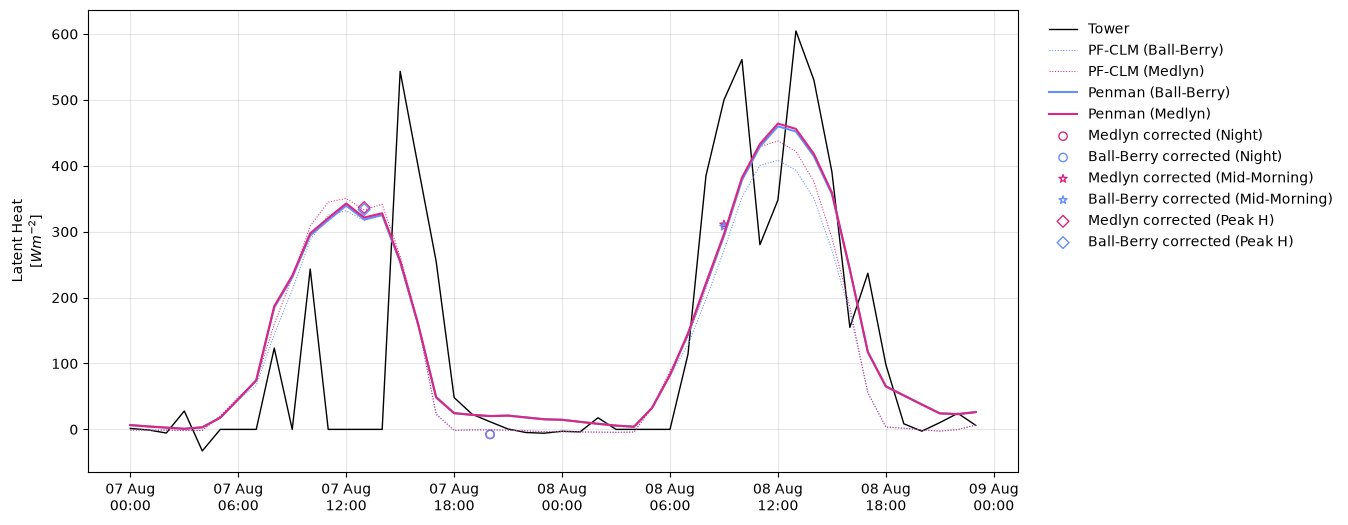

In [132]:
# compare both methods to the tower latent heat and to the two PF-CLM runs: one figure, hourly, all five series
fig, ax = plt.subplots(1, 1, figsize=(12,6))

# first plot the tower latent heat
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['tower_LE'], label='Tower', c='k', lw=1)
# next plot the two parflow clm runs
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['pfclm_lh_tot_bb'], label='PF-CLM (Ball-Berry)', c=IBM_BLUE, lw=0.75, ls=':')
ax.plot(hourly_data_combined['time_LST'], hourly_data_combined['pfclm_lh_tot_med'], label='PF-CLM (Medlyn)', c=IBM_PINK, lw=0.75, ls=':')
# next plot the penman versions
ax.plot(LE_df_q32['time_LST'], LE_df_q32['LE_BallBerry'], label='Penman (Ball-Berry)', c=IBM_BLUE, lw=1.5)
ax.plot(LE_df_q32['time_LST'], LE_df_q32['LE_Medlyn'], label='Penman (Medlyn)', c=IBM_PINK, lw=1.5)



# now define the parts to add to the curve
hr_night = '2016-08-07 20:00:00'        # random hour
hr_mid_morning = '2016-08-08 09:00:00'  # random hour
hr_peak_H = obs_df[obs_df.H == obs_df.H.max()].index.strftime('%Y-%m-%d %H:%M:%S').values[0]

# now compute the data
for hr, color, symbol, lab in zip([hr_night, hr_mid_morning, hr_peak_H], 
                                  [IBM_BLUE, IBM_PINK, IBM_ORANGE], ['o', '*', 'D'], 
                                  ['Night', 'Mid-Morning', 'Peak H']):
    # subset to the data
    subset_dat = obs_df[obs_df.index == hr]
    # compute the zeta
    zeta, psi_m, psi_v, ra_corr, _ = monin_obukhov_b211(
                    u=subset_dat.Wind.squeeze(),
                    z=30,
                    d0=d0_stn,
                    H=subset_dat.H.squeeze(),
                    T=subset_dat.Tair.squeeze()+ 273.15,
                    z0m=z0m_stn
                )

    out_dat = E_penman_from_df_corr(hourly_data_combined[hourly_data_combined.time_LST == hr], ra_corr)
    out_dat = pd.DataFrame(out_dat)
    #ra_ratio = compute_ratio(zeta, z0m_stn, d0_stn, 30)
    #print(f'{lab}: zeta: {zeta}, H: {subset_dat.H.squeeze():.2f}, ra_corr : {ra_corr:.2f}, ratio : {ra_ratio:.2f}, psi_m: {psi_m:.2f}, psi_v: {psi_v:.2f}')
    
    
    # now plot it on the curve
    #ax.scatter(zeta, ra_ratio, marker=symbol, facecolor='None', edgecolor=color, s=60, label=f"{lab} ({stab_lab}) - {hr}")
    ax.scatter(out_dat.time_LST, out_dat.LE_Medlyn, marker=symbol, edgecolor=IBM_PINK, facecolor='None', label=f'Medlyn corrected ({lab})')
    ax.scatter(out_dat.time_LST, out_dat.LE_BallBerry, marker=symbol, edgecolor=IBM_BLUE, facecolor='None', label=f'Ball-Berry corrected ({lab})')
    #ax.scatter(out_dat.time_LST, out_dat.LE_Avg, marker=symbol, edgecolor=IBM_PURPLE, facecolor='None', label=f'Average (ra corrected)')

    ax.legend()

ax.grid(alpha=0.3)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))

ax.set_ylabel('Latent Heat\n' + r'[$Wm^{-2}$]')

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

Here we see that the correction to Penman is actually largest at night rather than during peak heating hours, likely because the site does not become obviously water limited over our analysis period and instead the large correction at night is a mathematical feature of the correction functions. Specifically, the correction factor for stable conditions like those found at night for our tower are a linear function of the stability parameter, which is at the lowest value we allow in our function of -2 here, dividing the numerator in the Penman equation ($\Delta (R_n - G + \rho c_p (e_s(T_a) -e_a) / r_a$) by -10, further reducing whatever residual evaporaton the equation would predict from the vapor pressure deficit given the energy terms are effectively zero. By contrast, at peak H, the size of the correction factor will be smaller as the correction terms ($\psi_m$ and $\psi_v$) will be reduced by the logarithm and the arctan in their equations, and because the water limitation is not significant over the well irrigated field, the saturation vapor deficit in the numerator is not sufficent to be large enough to exceed that of stable conditions.

### 3.4 Daily-averaged inputs
Repeat 3.2 with daily averaged inputs and comapre to the hourly results averaged to daily. Explain the difference in terms of the Reynolds decomposition from the turbulent transport notes.

Note, assuming that I would only need to do this for my method.

Sanity Check: mean r_a: 165.48877297724505 s/m
Sanity Check: mean r_a: 165.48877297724505 s/m
Sanity Check: mean r_a: 165.48877297724505 s/m
Sanity Check: mean r_a: 165.48877297724505 s/m
Sanity Check: mean r_a: 165.48877297724505 s/m
Sanity Check: mean r_a: 165.48877297724505 s/m


Text(0.5, 0, 'Evaporation [w/m^2]')

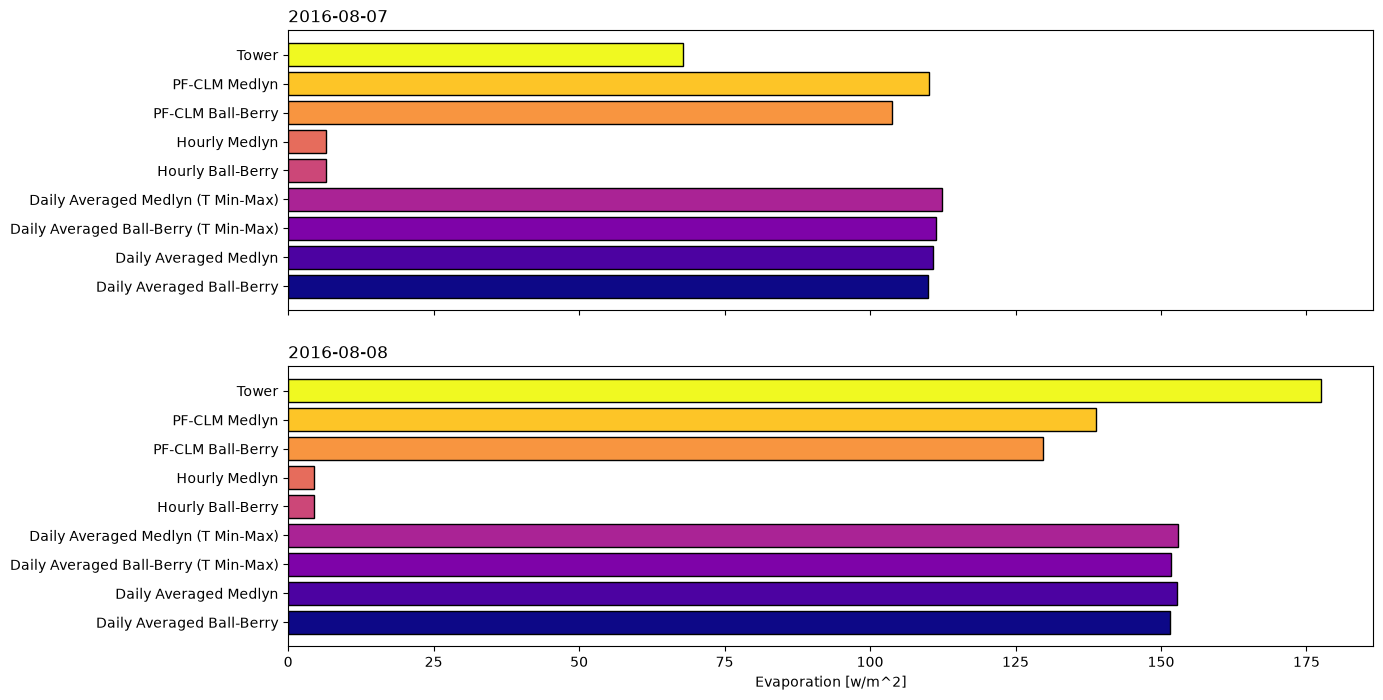

In [133]:
# take the daily average of the inputs for each day
hourly_data_combined['time_LST'] = pd.to_datetime(hourly_data_combined['time_LST'])
daily_groups = hourly_data_combined['time_LST'].dt.date 

# assuming just general mean for all quantities not min/max for temperature?
# add min-max for sanity check/comparison since I think in office hours was mentioned that FAO56 was min/max
daily_df = hourly_data_combined.drop(columns=['time_LST']).groupby(daily_groups).mean()
daily_min = hourly_data_combined.groupby(daily_groups)['air_temp_forcing'].min()
daily_max = hourly_data_combined.groupby(daily_groups)['air_temp_forcing'].max()
daily_df['air_temp_forcing_minmax'] = (daily_min + daily_max) / 2
daily_df = daily_df.reset_index().rename(columns={'time_LST': 'time_LST'})
daily_df.head()

# compute penman
LE_df_q34_tavg = pd.DataFrame(E_penman_from_df(daily_df))
LE_df_q34_tminmax = pd.DataFrame(E_penman_from_df(daily_df, temp_var='air_temp_forcing_minmax'))

# now get the daily average of the old hourly penman dataset for each day
LE_df_q32_avgd = LE_df_q32.groupby(LE_df_q32['time_LST'].dt.date).mean()

# PLOTTING
fig, ax = plt.subplots(2, 1, figsize=(14,8), sharex=True)
# plot them against the daily average of the tower and PF-CLM runs
bar_labels = ['Daily Averaged Ball-Berry', 'Daily Averaged Medlyn', 'Daily Averaged Ball-Berry (T Min-Max)', 'Daily Averaged Medlyn (T Min-Max)',
               'Hourly Ball-Berry', 'Hourly Medlyn', 'PF-CLM Ball-Berry', 'PF-CLM Medlyn', 'Tower']

bar_vals_0 = [LE_df_q34_tavg['LE_BallBerry'][0], LE_df_q34_tavg['LE_Medlyn'][0], LE_df_q34_tminmax['LE_BallBerry'][0], LE_df_q34_tminmax['LE_Medlyn'][0],
            LE_df_q32['LE_BallBerry'][0], LE_df_q32['LE_Medlyn'][0], daily_df['pfclm_lh_tot_bb'][0], daily_df['pfclm_lh_tot_med'][0], daily_df['tower_LE'][0]]

bar_vals_1 = [LE_df_q34_tavg['LE_BallBerry'][1], LE_df_q34_tavg['LE_Medlyn'][1], LE_df_q34_tminmax['LE_BallBerry'][1], LE_df_q34_tminmax['LE_Medlyn'][1],
            LE_df_q32['LE_BallBerry'][1], LE_df_q32['LE_Medlyn'][1], daily_df['pfclm_lh_tot_bb'][1], daily_df['pfclm_lh_tot_med'][1], daily_df['tower_LE'][1]]


cmap = plt.colormaps['plasma']
colors = cmap(np.linspace(0, 1, len(bar_labels)))

ax[0].barh(bar_labels, bar_vals_0, facecolor=colors, edgecolor='k')
ax[1].barh(bar_labels, bar_vals_1, facecolor=colors, edgecolor='k')

ax[0].set_title(f'{daily_df.time_LST[0]}', loc='left')
ax[1].set_title(f'{daily_df.time_LST[1]}', loc='left')

ax[1].set_xlabel('Evaporation [w/m^2]')

Explain the difference in terms of the Reynolds decomposition from the turbulent transport
notes.

We see that when using the daily average inputs to the Penman function, evaporation computed from both the Medlyn and Ball-Berry stomatal schemes is over 100 $W/m^2$ larger than when using the hourly estimates averaged across the day. This is because of how the

### 3.5 - Partitioning and Surface Resistance
Plot the PF-CLM soil evaporation, transpiration, and canopy evaporation for both runs against
the tower latent heat. Which one has the most midday flux? How do the Medlyn and Ball-Berry
runs differ?

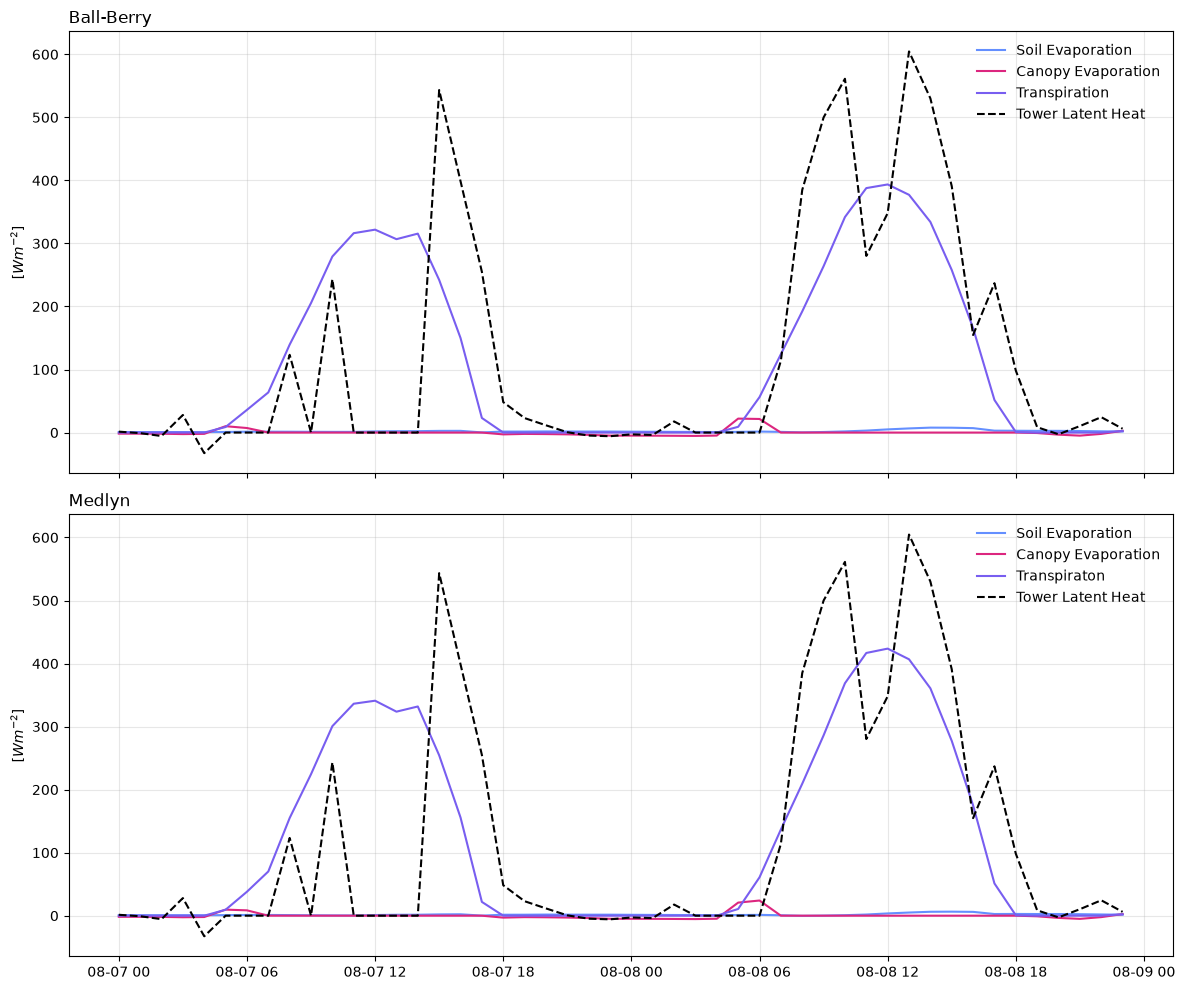

In [134]:
fig, ax = plt.subplots(2,1,figsize=(12,10), sharex=True)

ax[0].plot(clm_ds_ballberry.time, clm_ds_ballberry.qflx_evap_soi.squeeze() * 2.45e6, ls='-', c=IBM_BLUE, label='Soil Evaporation')
ax[1].plot(clm_ds_medlyn.time, clm_ds_medlyn.qflx_evap_soi.squeeze() * 2.45e6, ls='-', c=IBM_BLUE, label='Soil Evaporation')
ax[0].set_title('Ball-Berry', loc='left')

ax[0].plot(clm_ds_ballberry.time, (clm_ds_ballberry.qflx_evap_veg.squeeze() - clm_ds_ballberry.qflx_tran_veg.squeeze()) * 2.45e6, ls='-', c=IBM_PINK, label='Canopy Evaporation')
ax[1].plot(clm_ds_medlyn.time, (clm_ds_medlyn.qflx_evap_veg.squeeze() - clm_ds_medlyn.qflx_tran_veg.squeeze()) * 2.45e6, ls='-', c=IBM_PINK, label='Canopy Evaporation')
ax[1].set_title('Medlyn', loc='left')

ax[0].plot(clm_ds_ballberry.time, clm_ds_ballberry.qflx_tran_veg.squeeze() * 2.45e6, ls='-', c=IBM_PURPLE, label='Transpiration')
ax[1].plot(clm_ds_medlyn.time, clm_ds_medlyn.qflx_tran_veg.squeeze() * 2.45e6, ls='-', c=IBM_PURPLE, label='Transpiraton')

for a in ax.flatten():
    a.plot(hourly_data_combined.time_LST, hourly_data_combined.tower_LE, c='k', ls='--', label='Tower Latent Heat')
    a.grid(alpha=0.3)
    a.legend(ncols=1, frameon=False)
    a.set_ylabel(r'[$Wm^{-2}$]')

fig.tight_layout()


We see the most midday evaporation on both days comes from the transpiration flux, regardless of stomatal scheme, though we note that Medlyn produces marginally higher fluxes at the peak. Other than this, there is not much difference between Medlyn and Ball-Berry schemes. This is expected given that the field is well irrigated and unlikely to have much water limitation, meaning that in both cases, there is nothing to prompt the stomata to close and conserve water, especially on a clear day with no rapid changes in the atmospheric forcing that would change either the vapor pressure deficit, relative humidity or temperature that the two schemes use. Moreover, given the lack of water limitation, it is possible that there is a relativley humid canopy microclimate similar to that discussed in the Katul paper, which would keep conditions even more stable and thus stop the optimization parameters in Medlyn from diverging too much compared to Ball-Berry. Indeed, given that Medlyn optimizes the carbon gain and minimizes the water loss, yet is producing greater vapor flux than Ball-Berry, it is likely that the conditions at middday are sufficiently water-abundant to allow the stomata to be fully open without compromizing photosynthesis. We note that at the start of each day, canopy evaporation has a small spike, which we attribute to the evaporation of dew that may have condensed on the crops in the column, after which transpiration takes off due to the site being a well irrigated cropland. 

The remainder of 3.5 is by hand (see pdf), included the code I used to get the quantities from the dataframe

In [ ]:
print(f'Ball-Berry saturation: {pf_ds_ballberry.sel(time="2016-08-07 12:00:00").saturation.sel(z=1).values}')
print(f'Medlyn saturation: {pf_ds_medlyn.sel(time="2016-08-07 12:00:00").saturation.sel(z=1).values}')

print(f'Ball-Berry E_soil [wm^-2]: {clm_ds_ballberry.sel(time="2016-08-07 12:00:00").qflx_evap_soi.squeeze().values * 2.45e6}')
print(f'Medlyn E_soil [wm^-2]: {clm_ds_medlyn.sel(time="2016-08-07 12:00:00").qflx_evap_soi.squeeze().values * 2.45e6}')

print(f'Ball-Berry E_soil [wm^-2]: {clm_ds_ballberry.sel(time="2016-08-07 12:00:00").qflx_evap_soi.squeeze().values * 2.45e6}')
print(f'Medlyn E_soil [wm^-2]: {clm_ds_medlyn.sel(time="2016-08-07 12:00:00").qflx_evap_soi.squeeze().values * 2.45e6}')

Ball-Berry saturation: [[1.]]
Medlyn saturation: [[1.]]
Ball-Berry E_soil [wm^-2]: 1.7913215825979396
Medlyn E_soil [wm^-2]: 1.0548288277702642


In [164]:
print(f"Ball-Berry E_t: {(clm_ds_ballberry.qflx_tran_veg.squeeze()).sel(time="2016-08-07 12:00:00").values * 2.45e6}")
print(f"Medlyn E_t: {(clm_ds_medlyn.qflx_tran_veg.squeeze()).sel(time="2016-08-07 12:00:00").values * 2.45e6}")

print(f"Ball-Berry E: {(clm_ds_ballberry.qflx_evap_tot.squeeze()).sel(time="2016-08-07 12:00:00").values * 2.45e6}")
print(f"Medlyn E: {(clm_ds_medlyn.qflx_evap_tot.squeeze()).sel(time="2016-08-07 12:00:00").values * 2.45e6}")

Ball-Berry E_t: 321.9038066976074
Medlyn E_t: 341.0468955038384
Ball-Berry E: 323.6951282774945
Medlyn E: 342.10172432797367


In [152]:
pf_ds_ballberry.sel(time="2016-08-07 12:00:00").saturation.values

array([[[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[0.9996851 ]],

       [[0.92757691]],

       [[0.82004355]],

       [[0.76386288]]])

In [ ]:
pf_ds_medlyn.sel(time="2016-08-07 12:00:00").saturation.values  # note from bottom up

array([[[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[1.        ]],

       [[0.99967667]],

       [[0.92725978]],

       [[0.81944343]],

       [[0.76317437]]])

In [155]:
pf_ds_ballberry.sel(time="2016-08-07 12:00:00")

<xarray.Dataset> Size: 168B
Dimensions:     (z: 10, y: 1, x: 1)
Coordinates:
    time        datetime64[us] 8B 2016-08-07T12:00:00
Dimensions without coordinates: z, y, x
Data variables:
    pressure    (z, y, x) float64 80B ...
    saturation  (z, y, x) float64 80B ...

In [158]:
hourly_data_combined.iloc[12]

time_LST            2016-08-07 12:00:00
air_temp_forcing               298.8369
pressure_forcing               98497.67
spechum_forcing                0.012761
windsp_forcing                 1.882556
swdn_forcing                   639.4949
lwdn_forcing                   385.8239
pfclm_tgrnd_bb               297.205263
pfclm_tgrnd_med              296.993902
pfclm_lh_tot_bb              331.675204
pfclm_lh_tot_med             350.535579
pfclm_sh_tot_bb               76.952374
pfclm_sh_tot_med              62.446854
tower_LE                            0.0
tower_H                       43.964113
Name: 12, dtype: object